# Modelado y evaluacion: prediccion de la popularidad de canciones de Spotify
## Ridge, Random Forest y XGBoost, cada uno con la preparacion de datos que necesita

| | |
|---|---|
| **Asignatura** | MLY1101 Machine Learning |
| **Evaluacion** | Parcial Nro. 2: presentacion y defensa tecnica del proyecto |
| **Equipo** | Grupo 5: Cristian Romero y Rolando Paredes |
| **Caso** | C: inteligencia musical y prediccion de popularidad de canciones (Spotify Tracks) |
| **Metodologia** | CRISP-DM: fase 4 (modelado) y fase 5 (evaluacion). Las fases 1 a 3 estan en la EV1 |
| **Entrada** | Los datos que exporta el notebook de la EV1 (carpeta `data/processed/`) |
| **Informe** | `ev2/Informe_ev2.md` resume este notebook; aqui esta el respaldo de cada cifra |

### Indice

1. Pregunta de investigacion y metodo
2. Contexto del problema y de los datos
3. Configuracion y protocolo de evaluacion
4. Los tres modelos: como funcionan y que necesitan
5. Preparacion propia de cada modelo, hipotesis por hipotesis
6. Preparacion final contra la preparacion de la EV1
7. Errores, criterios de exito y protocolo de seleccion
8. Escenario cancion inedita
9. Interpretacion del modelo candidato
10. Auditoria de sesgos con el modelo
11. Conclusiones y recomendaciones
12. Limitaciones, proximos pasos y reproducibilidad

---
# 1. Pregunta de investigacion y metodo

## 1.1 Que responde este notebook

La EV1 dejo los datos limpios y una preparacion unica para cualquier modelo: genero codificado por objetivo, Yeo-Johnson en las variables asimetricas y estandarizacion. Pero cada modelo aprende de una forma distinta y no necesita lo mismo. La pregunta de esta etapa es:

> **¿Preparar los datos segun lo que necesita cada modelo mejora los resultados frente a usar la preparacion de la EV1 para todos?**

**Lo unico que cambia es la preparacion de los datos.** Los tres modelos usan sus parametros y su funcion de perdida por defecto. Elegir esos valores es el ajuste de hiperparametros, que corresponde a la etapa siguiente.

## 1.2 Metodo: una hipotesis a la vez

Para cada modelo se repite el mismo ciclo, partiendo de la preparacion de la EV1:

1. **Hipotesis.** Que podria necesitar el modelo, segun su documentacion oficial o segun una idea propia sacada del EDA de la EV1.
2. **Prueba.** Se cambia una sola cosa de la preparacion vigente, se entrena y se evalua con validacion cruzada.
3. **Veredicto.** Mejora, empeora o no tiene efecto (regla fija en 3.5). Se anota en la bitacora.
4. **Decision.** Si mejora, el cambio se adopta y la siguiente hipotesis parte de ahi. Si no, se sigue con la preparacion vigente.

Al terminar los tres modelos, cada uno se prueba ademas con **todos los cambios propuestos a la vez** (5.5), por si juntos suman aunque por separado no hicieran nada. Luego la preparacion final de cada modelo se compara con la de la EV1 (seccion 6). La prueba se usa una sola vez, al final.

| Requisito de la pauta | Donde esta |
|---|---|
| Problema de negocio y objetivos | 2.1 |
| Fuentes de datos | 2.2 y 2.3 |
| EDA | EV1; resumen en 2.4 |
| Preparacion y transformacion | 5 |
| Justificacion de los modelos (minimo 3) | 4 |
| Variables finales por modelo | 6.1 |
| Implementacion | 3 y 6.2 |
| Evaluacion y seleccion | 6, 7 y 11 |

## 1.3 Hipotesis y veredictos

Se escribieron antes de medir. La seccion 5 tiene el detalle de cada una.

| # | Modelo | Hipotesis | Fuente | Veredicto |
|---|---|---|---|---|
| R1 | Ridge | El genero en one-hot rinde igual que codificado por objetivo | Documentacion | Confirmada |
| R2 | Ridge | Escalar las binarias mejora el resultado | Documentacion | No confirmada |
| R3 | Ridge | Quitar Yeo-Johnson empeora el resultado | Documentacion | Parcial |
| R4 | Ridge | Splines en las variables con forma de U invertida mejoran el resultado | Propia (EDA) | No confirmada |
| F1 | Random Forest | Quitar Yeo-Johnson y escalado no cambia el resultado | Documentacion | Confirmada |
| F2 | Random Forest | El genero en one-hot empeora el resultado | Documentacion | Refutada: mejora |
| F3 | Random Forest | Recuperar `instrumentalness` y `key` mejora el resultado | Propia (EV1) | No confirmada |
| X1 | XGBoost | Quitar Yeo-Johnson y escalado no cambia el resultado | Documentacion | Confirmada |
| X2 | XGBoost | El genero como categoria nativa mejora el resultado | Documentacion | Confirmada |
| X3 | XGBoost | Recuperar `instrumentalness` y `key` mejora el resultado | Propia (EV1) | No confirmada |
| T | Los tres | Todos los cambios propuestos juntos mejoran a algun modelo | Propia | No confirmada |

## 1.4 Hallazgos principales

- **Adaptar la preparacion mejora a los dos modelos de arboles y no a Ridge.** XGBoost baja su MAE de prueba de 11,30 a 10,64 gracias al genero como categoria nativa. Random Forest baja de 10,99 a 10,85 con el genero en one-hot. Para Ridge, la preparacion de la EV1 ya era la adecuada: ninguno de los cuatro cambios supero el ruido.
- **La preparacion cambia el orden de los modelos.** Con la preparacion de la EV1, Random Forest es el mejor y XGBoost el segundo. Con la preparacion propia, XGBoost pasa al primer lugar.
- **Ningun modelo cumple los seis criterios de exito de la EV1.** Por el protocolo de seleccion (3.5), XGBoost con preparacion propia queda como **mejor candidato, pero todavia no apto**: cumple MAE y equidad, y no cumple RMSE, R², error en exitos ni sobreajuste.
- **El genero explica casi todo** (72% de la importancia) y los exitos se subestiman en unos 29 puntos.

---
# 2. Contexto del problema y de los datos

## 2.1 Problema de negocio y objetivos

Un sello o una plataforma decide en que canciones invertir (promocion, playlists, artistas) muchas veces cuando el exito ya ocurrio. El proyecto estima la popularidad de una cancion (0 a 100) a partir de su audio, su genero y metadatos basicos, como apoyo a esas decisiones.

**Objetivo de esta etapa:** preparar los datos segun lo que necesita cada modelo, entrenar y comparar tres modelos de regresion, saber cual rinde mejor y por que, y verificar los criterios de exito de la EV1.

## 2.2 El dataset

| Atributo | Valor |
|---|---|
| Fuente | Spotify Tracks Dataset, Kaggle (*maharshipandya*), construido con la Web API de Spotify |
| Original | 114.000 filas y 21 columnas; aprox. 1.000 canciones por cada uno de 114 generos |
| Tras la limpieza de la EV1 | 85.859 canciones: 68.704 de entrenamiento y 17.155 de prueba, divididas agrupando por cancion |
| Objetivo | `popularity` (entero de 0 a 100) |

## 2.3 Glosario de datos

### 2.3.1 Variables del archivo original

Es el mismo glosario de la EV1 (`ev1/notebook_ev1.ipynb`, seccion 2.4).

| Variable | Descripcion | Tipo | Rango / valores | Rol en el proyecto |
|---|---|---|---|---|
| `Unnamed: 0` | Indice de fila exportado junto al CSV | Identificador (artefacto) | 0 a 113.999 | Eliminada en la EV1 |
| `track_id` | Identificador de un lanzamiento en Spotify (la misma grabacion en un single y en un album tiene dos `track_id`) | Identificador | Texto de 22 caracteres | Trazabilidad; excluida del modelo |
| `artists` | Artista(s), separados por `;` | Texto libre | 31.437 valores | Agrupa la division y la validacion cruzada; origen de `n_artistas` |
| `album_name` | Album en que aparece la cancion | Texto libre | 46.589 valores | Excluida del modelo |
| `track_name` | Titulo de la cancion | Texto libre | 73.608 valores | Agrupa la division y la validacion cruzada |
| `popularity` | Popularidad calculada por Spotify, basada en reproducciones recientes | Numerica discreta | 0 a 100 | **Variable objetivo** |
| `duration_ms` | Duracion en milisegundos | Numerica continua | > 0 | Reemplazada por `duracion_min` |
| `explicit` | Letras explicitas (falso tambien puede significar desconocido) | Binaria | True / False | Predictor (0/1) |
| `danceability` | Que tan apta es para bailar | Numerica continua | 0,0 a 1,0 | Predictor |
| `energy` | Intensidad percibida | Numerica continua | 0,0 a 1,0 | Predictor |
| `key` | Tonalidad (0 = Do ... 11 = Si) | Categorica nominal | 0 a 11 | Excluida en la EV1; se pone a prueba en F3 y X3 |
| `loudness` | Volumen promedio en dB | Numerica continua | Aprox. -60 a 0 | Predictor |
| `mode` | Mayor (1) o menor (0) | Binaria | 0 / 1 | Predictor |
| `speechiness` | Presencia de palabra hablada | Numerica continua | 0,0 a 1,0 | Predictor; en la EV1 definio un filtro |
| `acousticness` | Confianza de que sea acustica | Numerica continua | 0,0 a 1,0 | Predictor |
| `instrumentalness` | Probabilidad de que no tenga voz | Numerica continua | 0,0 a 1,0 | Reemplazada por `es_instrumental` en la EV1; se pone a prueba en F3 y X3 |
| `liveness` | Probabilidad de que sea en vivo | Numerica continua | 0,0 a 1,0 | Predictor |
| `valence` | Positividad musical | Numerica continua | 0,0 a 1,0 | Predictor |
| `tempo` | Tempo en BPM | Numerica continua | > 0 | Predictor |
| `time_signature` | Compas estimado | Categorica ordinal | Documentado de 3 a 7 | Reemplazada por `compas_4_4` |
| `track_genre` | Genero con que se recupero la cancion | Categorica nominal | 113 categorias tras unificar `songwriter` | Predictor; cada modelo lo recibe distinto (5) |

### 2.3.2 Variables construidas en la EV1

| Variable | Calculo | Tipo | Rango | Rol |
|---|---|---|---|---|
| `duracion_min` | `duration_ms / 60000` | Numerica continua | 0,26 a 87,29 | Predictor |
| `n_artistas` | Artistas que firman la cancion | Numerica discreta | 1 a 38 | Predictor |
| `n_generos` | Generos en que aparecia la cancion antes de dejar una fila por cancion | Numerica discreta | 1 a 8 | Predictor; no existe para una cancion inedita (8) |
| `es_instrumental` | 1 si `instrumentalness > 0,5` | Binaria | 0 / 1 | Predictor |
| `compas_4_4` | 1 si `time_signature == 4` | Binaria | 0 / 1 | Predictor |

## 2.4 Lo que dejo la EV1

- **Limpieza:** de 114.000 a 85.859 canciones. Se quitaron 450 duplicados exactos, 22.809 copias de canciones repetidas por genero, 157 filas con audio sin analizar (`tempo = 0`), 868 de contenido casi solo hablado y 2.856 versiones con popularidad 0 artificial. La duracion no se filtro.
- **Hallazgos:** el genero explica cerca del 35% de la varianza (η² = 0,351). El audio se relaciona poco y de forma no lineal (ninguna correlacion supera 0,13; forma de U invertida en `energy`, `danceability` y duracion). Hay asimetria fuerte en duracion, habla, vivo y volumen, y colinealidad moderada entre `energy`, `loudness` y `acousticness` (hasta 0,76; VIF final ≤ 4,34).
- **Preparacion unica:** genero codificado por objetivo, Yeo-Johnson en 6 variables asimetricas y `StandardScaler` en las continuas. `instrumentalness` se excluyo por su VIF junto a `es_instrumental` y `key` porque necesitaba 11 columnas one-hot sin relacion con la popularidad.
- **Sesgos:** muestreo artificial por genero, efecto superestrella (el artista explica mas que el genero) y factores que no estan en los datos: promocion, redes sociales, seguidores y fama.

## 2.5 Criterios de exito (EV1, sin cambios)

| Criterio | Umbral |
|---|---|
| R² en prueba | ≥ 0,40 |
| RMSE en prueba | ≤ 15,51 (77% de la linea base) |
| MAE en prueba | ≤ 13,46 (80% de la linea base) |
| Brecha de R² entre entrenamiento y prueba | ≤ 0,05 |
| MAE en canciones de popularidad ≥ 70 | ≤ 20 (la linea base comete 41,2) |
| Brecha de MAE entre cuartiles de genero | ≤ 5 (la linea base tiene 6,1) |

No se usa MAPE: el 7,6% de las canciones tiene popularidad 0 y el error porcentual no esta definido para ellas.

---
# 3. Configuracion y protocolo de evaluacion

## 3.1 Librerias y configuracion

Semilla unica, rutas relativas a la raiz del proyecto y paleta fija (azul = preparacion propia, naranjo = preparacion de la EV1, gris = referencias). No se silencia ningun aviso de las librerias.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import sklearn, xgboost
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler, TargetEncoder, OneHotEncoder, SplineTransformer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

# No se silencia ningun aviso de las librerias
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 70)

SEMILLA = 42
np.random.seed(SEMILLA)
# Raiz del proyecto: se sube desde la carpeta actual hasta encontrar data/raw
# (funciona igual si se ejecuta desde ev2/ o desde la raiz)
from pathlib import Path
RAIZ = Path.cwd()
while not (RAIZ / 'data' / 'raw').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
DATOS_RAW = RAIZ / 'data' / 'raw'
CARPETA = RAIZ / 'data' / 'processed'      # entrada: archivos que exporta el notebook de la EV1
IMAGENES = RAIZ / 'ev2' / 'images'
os.makedirs(IMAGENES, exist_ok=True)

COLOR_ADAPT, COLOR_EV1, COLOR_NEUTRO, COLOR_TEXTO = '#2a78d6', '#eb6834', '#8c8b86', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.edgecolor': '#b9b8b2'})


def guardar_figura(fig, nombre):
    # Guarda la figura en ev2/images para insertarla en el informe (Informe_ev2.md)
    fig.savefig(IMAGENES / f'{nombre}.png', dpi=110, bbox_inches='tight')

def estilo(ax, titulo, xlabel=None, ylabel=None, grilla='y'):
    ax.set_title(titulo, loc='left', fontsize=11, fontweight='bold', color='#0b0b0b')
    if xlabel: ax.set_xlabel(xlabel, color=COLOR_TEXTO)
    if ylabel: ax.set_ylabel(ylabel, color=COLOR_TEXTO)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
    ax.tick_params(colors=COLOR_TEXTO)
    ax.grid(axis=grilla, color='#e6e5e0', linewidth=0.8)
    ax.set_axisbelow(True)

print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| xgboost', xgboost.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | xgboost 3.4.1


## 3.2 Carga de los datos de la EV1

| Version | Contenido | Uso |
|---|---|---|
| **Base** | Las 16 variables limpias, con `track_genre` como texto y sin transformar | Punto de partida de toda preparacion; dentro de cada fold se aplica la preparacion que corresponde |
| **Procesada EV1** | Genero codificado por objetivo, Yeo-Johnson y estandarizacion | Sirve para comprobar que la preparacion de la EV1 rearmada aqui es identica a la original (5.0) |

Se comprueba que las filas de todas las tablas correspondan a la misma cancion; si no, nada de lo que sigue seria valido.

In [2]:
leer = lambda nombre: pd.read_csv(CARPETA / nombre)

X_base_train, X_base_test = leer('X_train_base.csv'), leer('X_test_base.csv')
X_proc_train, X_proc_test = leer('X_train_procesado_ev1.csv'), leer('X_test_procesado_ev1.csv')
y_train, y_test = leer('y_train.csv')['popularity'], leer('y_test.csv')['popularity']
ids_train, ids_test = leer('ids_train.csv'), leer('ids_test.csv')
grupos_train = ids_train['grupo_cancion']          # una cancion = un grupo (artista + titulo)
with open(CARPETA / 'metadatos_preprocesamiento.json', encoding='utf-8') as f:
    meta = json.load(f)

print(f'Entrenamiento: {X_base_train.shape[0]:,} canciones | Prueba: {X_base_test.shape[0]:,} canciones')
print('Filas alineadas (train):', len(X_base_train) == len(X_proc_train) == len(y_train) == len(ids_train))
print('Filas alineadas (test) :', len(X_base_test) == len(X_proc_test) == len(y_test) == len(ids_test))
print('Canciones compartidas entre train y test:', len(set(ids_train['grupo_cancion']) & set(ids_test['grupo_cancion'])))
print('Generos en test que no estan en train   :', set(X_base_test['track_genre']) - set(X_base_train['track_genre']))
print('Nulos en la version base (train / test) :', X_base_train.isnull().sum().sum(), '/', X_base_test.isnull().sum().sum())
X_base_train.head()

Entrenamiento: 68,704 canciones | Prueba: 17,155 canciones
Filas alineadas (train): True
Filas alineadas (test) : True
Canciones compartidas entre train y test: 0
Generos en test que no estan en train   : set()
Nulos en la version base (train / test) : 0 / 0


,explicit,danceability,energy,loudness,mode,speechiness,acousticness,liveness,valence,tempo,track_genre,n_generos,duracion_min,n_artistas,es_instrumental,compas_4_4
0,0,0.420,0.166,-17.235,1,0.076,0.924,0.101,0.267,77.489,acoustic,2,2.494,1,0,1
1,0,0.438,0.359,-9.734,1,0.056,0.210,0.117,0.120,76.332,acoustic,1,3.514,2,0,1
2,0,0.266,0.060,-18.515,1,0.036,0.905,0.132,0.143,181.740,acoustic,1,3.366,1,0,0
3,0,0.618,0.443,-9.681,1,0.053,0.469,0.083,0.167,119.949,acoustic,1,3.314,1,0,1
4,0,0.703,0.444,-9.331,1,0.042,0.559,0.097,0.712,150.960,acoustic,2,4.049,1,0,1


## 3.3 Tipo de cada variable

| Grupo | Por que se separa |
|---|---|
| Continuas con asimetria fuerte (> 1 en valor absoluto) | La EV1 les aplico Yeo-Johnson; se pone a prueba si cada modelo lo necesita |
| Continuas restantes | Solo escalado en la EV1 |
| Binarias | Ya estan en 0/1; la EV1 no las escalo |
| `track_genre` (113 generos) | Su formato es la decision que mas depende del modelo |

In [3]:
bin_ = meta['columnas_binarias']
yj = meta['columnas_con_yeo_johnson']
cont = [c for c in meta['columnas_base'] if c not in bin_ + ['track_genre']]

resumen_vars = pd.DataFrame({
    'asimetria': X_base_train[cont].skew(),
    'minimo': X_base_train[cont].min(),
    'maximo': X_base_train[cont].max(),
    'desviacion': X_base_train[cont].std(),
}).sort_values('asimetria', key=abs, ascending=False)
resumen_vars['Yeo-Johnson en la EV1'] = resumen_vars.index.isin(yj)
display(resumen_vars)

print('\nBinarias: porcentaje de canciones con valor 1')
print((X_base_train[bin_].mean() * 100).round(1).to_string())
conteo_gen = X_base_train['track_genre'].value_counts()
print(f"\nGeneros: {conteo_gen.size} | canciones por genero: minimo {conteo_gen.min()}, mediana {conteo_gen.median():.0f}, maximo {conteo_gen.max()}")
print(f"Popularidad en train: media {y_train.mean():.1f}, mediana {y_train.median():.0f}, "
      f"{(y_train == 0).mean() * 100:.1f}% con popularidad 0, {(y_train >= 70).mean() * 100:.1f}% con 70 o mas")

# Parte de la varianza de popularidad que explica el genero por si solo (eta cuadrado, en train)
media_gen_train = y_train.groupby(X_base_train['track_genre']).transform('mean')
eta2_genero = 1 - ((y_train - media_gen_train) ** 2).sum() / ((y_train - y_train.mean()) ** 2).sum()
print(f"El genero por si solo explica {eta2_genero * 100:.1f}% de la varianza de la popularidad en train")

,asimetria,minimo,maximo,desviacion,Yeo-Johnson en la EV1
duracion_min,11.742,0.263,87.288,1.923,True
n_artistas,6.636,1.000,32.000,0.863,True
n_generos,3.346,1.000,8.000,0.610,True
speechiness,2.807,0.022,0.659,0.080,True
liveness,2.122,0.009,1.000,0.188,True
loudness,-1.938,-46.591,4.532,5.219,True
acousticness,0.681,0.000,0.996,0.337,False
energy,-0.553,0.000,1.000,0.258,False
danceability,-0.358,0.051,0.985,0.177,False
tempo,0.287,30.200,243.372,29.677,False



Binarias: porcentaje de canciones con valor 1
explicit           8.000
mode              63.700
es_instrumental   19.300
compas_4_4        89.100

Generos: 113 | canciones por genero: minimo 184, mediana 657, maximo 820
Popularidad en train: media 34.3, mediana 35, 7.6% con popularidad 0, 3.6% con 70 o mas
El genero por si solo explica 35.2% de la varianza de la popularidad en train


## 3.4 Validacion cruzada y linea base

`GroupKFold` de 5 folds dentro del entrenamiento, con grupos = cancion (artista + titulo). Cada grupo aparece exactamente una vez en validacion $_{[1]}$, asi que dos versiones de una misma cancion nunca quedan en lados opuestos. La linea base predice siempre la media de entrenamiento: un modelo que no la supere no aporta nada.

In [4]:
def metricas(y, p):
    return {'MAE': mean_absolute_error(y, p), 'RMSE': np.sqrt(mean_squared_error(y, p)), 'R2': r2_score(y, p)}

FOLDS = list(GroupKFold(n_splits=5).split(X_base_train, y_train, groups=grupos_train))
print('Folds de validacion (filas de entrenamiento, filas de validacion):', [(len(a), len(b)) for a, b in FOLDS])

baseline = DummyRegressor(strategy='mean').fit(X_base_train, y_train)
pred_base = baseline.predict(X_base_test)
m_base = metricas(y_test, pred_base)
alta_test = y_test >= 70

umbral_mae, umbral_rmse = 0.80 * m_base['MAE'], 0.77 * m_base['RMSE']
mae_exitos_base = mean_absolute_error(y_test[alta_test], pred_base[alta_test])

print('\n=== Linea base (predice la media de train) sobre test ===')
print(f"MAE  : {m_base['MAE']:.2f}  -> umbral de exito (80%): {umbral_mae:.2f}")
print(f"RMSE : {m_base['RMSE']:.2f}  -> umbral de exito (77%): {umbral_rmse:.2f}")
print(f"R2   : {m_base['R2']:.4f}")
print(f"MAE en canciones con popularidad >= 70 ({alta_test.sum()} canciones): {mae_exitos_base:.2f}")

Folds de validacion (filas de entrenamiento, filas de validacion): [(54963, 13741), (54963, 13741), (54963, 13741), (54963, 13741), (54964, 13740)]

=== Linea base (predice la media de train) sobre test ===
MAE  : 16.83  -> umbral de exito (80%): 13.46
RMSE : 20.15  -> umbral de exito (77%): 15.51
R2   : -0.0003
MAE en canciones con popularidad >= 70 (657 canciones): 41.19


## 3.5 Protocolo de evaluacion y de seleccion

Se fija aqui, antes de preparar o entrenar, para que ninguna decision se ajuste a los resultados.

**Como se mide**

1. **La prueba se usa una sola vez**, al final (seccion 6), para todas las configuraciones a la vez.
2. **Todas las decisiones salen de la validacion cruzada.** Toda preparacion que aprende de los datos (codificador, Yeo-Johnson, escalado) va dentro de un `Pipeline` y se reajusta en cada fold.
3. **Parametros por defecto en los tres modelos.** Lo unico que se compara es la preparacion.

**Metricas.** MAE (principal: puntos que se equivoca en promedio), RMSE (castiga mas los errores grandes) y R² (parte de la variacion que explica el modelo; 0 equivale a predecir el promedio).

**Regla para cada hipotesis (seccion 5)**

El **ruido** es la desviacion del MAE entre los 5 folds de la preparacion vigente (entre 0,05 y 0,09 puntos). Equivale a unas dos veces el error estandar del promedio de 5 folds, asi que una diferencia mayor que el ruido dificilmente es azar.

| Resultado del cambio | Veredicto | Decision |
|---|---|---|
| Baja el MAE en mas que el ruido | Mejora | Se adopta |
| Sube el MAE en mas que el ruido | Empeora | Se descarta |
| Cambia menos que el ruido | Sin efecto | Se mantiene la preparacion vigente, salvo que la documentacion del modelo diga que el paso que se quita no hace falta: ahi se adopta la version mas simple |

Ademas se anota en cuantos de los 5 folds mejora el cambio, como dato de apoyo.

**Protocolo de seleccion (se aplica en 7.3)**

| Paso | Regla |
|---|---|
| 1 | Una preparacion propia es **apta** solo si cumple los seis criterios de exito en prueba (2.5) |
| 2 | Entre las aptas, gana la de menor MAE en **validacion** (no en prueba, para no elegir con la prueba) |
| 3 | Si otra queda a menos del ruido del lider, se consideran empatadas y gana la mas interpretable (Ridge antes que los arboles) |
| 4 | Los umbrales no se bajan. Si ninguna es apta, la ganadora de los pasos 2 y 3 queda como **mejor candidata** para la etapa siguiente (ajuste de hiperparametros), no como modelo listo para usar |

Las configuraciones con la preparacion de la EV1 son el punto de comparacion: miden el efecto de la preparacion, no compiten.

---
# 4. Los tres modelos: como funcionan y que necesitan

Lo que dice la documentacion oficial lleva un numero, como $_{[1]}$ (lista al final). Lo que se deduce de ahi se marca como **razonamiento**.

## 4.1 Por que estos tres

Tres formas distintas de aprender, para que la comparacion diga algo sobre los datos y no sobre un solo algoritmo.

| | **Ridge** | **Random Forest** | **XGBoost** |
|---|---|---|---|
| Familia | Lineal regularizado | Arboles en paralelo (bagging) | Arboles en secuencia (boosting) |
| Como aprende | Minimiza el error cuadratico mas un castigo a los coeficientes grandes $_{[6]}$ | Promedia arboles entrenados con muestras al azar de las filas $_{[5]}$ | Cada arbol nuevo corrige el error de los anteriores, con un termino que castiga arboles complejos $_{[8]}$ |
| Por que encaja | Es la referencia interpretable; el castigo hace los coeficientes "more robust to collinearity" $_{[2]}$, util con `energy`, `loudness` y `acousticness` correlacionadas | Capta relaciones no lineales, como la U invertida del audio, sin programarlas (razonamiento) | Acepta el genero como categoria y agrupa generos en cada corte $_{[3]}$ |
| Limitacion | Solo relaciones lineales en lo que recibe | Con `max_depth=None` los arboles crecen sin limite y tienden a memorizar $_{[5]}$ | Por defecto no esta ajustado a estos datos |

## 4.2 Que dice la documentacion que necesita cada uno

| Aspecto | **Ridge** | **Random Forest** | **XGBoost** |
|---|---|---|---|
| Escala | **Importa**: los regularizadores l1 y l2 de los modelos lineales suponen variables con "variance in the same order" $_{[7]}$ | Los arboles requieren "little data preparation" y no necesitan normalizar $_{[13]}$ | Igual que Random Forest: tambien son arboles $_{[13]}$ (razonamiento) |
| Asimetria | Puede importar: un modelo lineal recibe la forma de la variable tal cual (razonamiento) | Un corte "variable < umbral" no cambia con una transformacion que conserva el orden (razonamiento) | Igual que Random Forest (razonamiento) |
| Genero (113 niveles) | Necesita numeros. El one-hot es "better suited for low cardinality" $_{[10]}$; la codificacion por objetivo entrega una columna | Necesita numeros; la implementacion de scikit-learn no acepta categorias $_{[13]}$ | Puede recibirlo como categoria: busca agrupar "the categories that output similar leaf values" $_{[3]}$ |
| Relaciones no lineales | No las capta solo; se le pueden entregar con splines, "piecewise polynomials" $_{[7,14]}$ | Las capta | Las capta |

## 4.3 Herramientas de preparacion

| Herramienta | Que hace | Fuente |
|---|---|---|
| `StandardScaler` | Resta la media y divide por la desviacion | $_{[7]}$ |
| `PowerTransformer` (Yeo-Johnson) | Reduce la asimetria; admite ceros y negativos | $_{[7,9]}$ |
| `OneHotEncoder` | Una columna 0/1 por categoria | $_{[7]}$ |
| `TargetEncoder` | Reemplaza cada categoria por la media del objetivo, suavizada; en `fit_transform` usa *cross fitting* "to prevent target leakage" $_{[10]}$ | $_{[10]}$ |
| `SplineTransformer` | Reemplaza una variable por varias curvas por tramos; con `knots='quantile'` los tramos siguen los cuantiles de la variable $_{[14]}$ | $_{[7,14]}$ |
| Categoria nativa de XGBoost | El arbol agrupa categorias en cada corte | $_{[3]}$ |

In [5]:
# Los tres modelos con sus parametros por defecto: lo unico que cambia en este notebook es la preparacion
def crear_modelo(tipo):
    if tipo == 'ridge':
        return Ridge()
    if tipo == 'rf':
        return RandomForestRegressor(random_state=SEMILLA, n_jobs=-1)
    if tipo == 'xgb':
        # enable_categorical solo permite recibir columnas category; no cambia el entrenamiento si no las hay
        return XGBRegressor(enable_categorical=True, random_state=SEMILLA, n_jobs=-1)

NOMBRES = {'ridge': 'Ridge', 'rf': 'Random Forest', 'xgb': 'XGBoost'}
claves = {'ridge': ['alpha', 'fit_intercept', 'solver'], 'rf': ['n_estimators', 'criterion', 'max_depth', 'min_samples_leaf', 'max_features'],
          'xgb': ['n_estimators', 'objective', 'learning_rate', 'max_depth', 'tree_method']}
for tipo, ks in claves.items():
    p = crear_modelo(tipo).get_params()
    print(f"{NOMBRES[tipo]:14s}", {k: p[k] for k in ks})
config_xgb = json.loads(XGBRegressor().fit(X_base_train[['energy']].head(50), y_train.head(50)).get_booster().save_config())
param_arbol = config_xgb['learner']['gradient_booster']['tree_train_param']
print('XGBoost (valores efectivos):', {k: param_arbol[k] for k in ['eta', 'max_depth', 'max_cat_to_onehot']},
      '| arboles:', config_xgb['learner']['gradient_booster']['gbtree_model_param']['num_trees'])

Ridge          {'alpha': 1.0, 'fit_intercept': True, 'solver': 'auto'}
Random Forest  {'n_estimators': 100, 'criterion': 'squared_error', 'max_depth': None, 'min_samples_leaf': 1, 'max_features': 1.0}
XGBoost        {'n_estimators': None, 'objective': 'reg:squarederror', 'learning_rate': None, 'max_depth': None, 'tree_method': None}
XGBoost (valores efectivos): {'eta': '0.300000012', 'max_depth': '6', 'max_cat_to_onehot': '4'} | arboles: 100


**Lectura.** Ridge usa `alpha = 1`. Random Forest usa 100 arboles sin limite de profundidad y todas las variables en cada corte (`max_features = 1,0`). XGBoost usa 100 arboles, `eta = 0,3`, `max_depth = 6` y la perdida cuadratica; con 113 generos usa la particion de categorias y no el one-hot, porque supera `max_cat_to_onehot = 4` $_{[4]}$. Nada de esto se modifica en el notebook.

---
# 5. Preparacion propia de cada modelo, hipotesis por hipotesis

Cada hipotesis sigue el mismo formato: **hipotesis** (que se espera y por que), **fuente** (documentacion o idea propia), **prueba** (que cambia), **evidencia** (las cifras), **veredicto** y **costo de no hacerlo** (que se pierde si se deja la preparacion de la EV1).

## 5.0 Herramientas

Una preparacion se describe con un diccionario; cada hipotesis cambia una sola clave.

| Clave | Opciones | Preparacion de la EV1 |
|---|---|---|
| `continuas` | `yj_escalar` (Yeo-Johnson en las 6 asimetricas + escalado), `escalar`, `sin_cambio` | `yj_escalar` |
| `binarias` | `sin_cambio`, `escalar` (si el genero va en one-hot, tambien escala esas columnas) | `sin_cambio` |
| `genero` | `objetivo_escalado`, `objetivo`, `onehot`, `nativo` | `objetivo_escalado` |
| `splines` | Splines en `energy`, `danceability` y `duracion_min` | No |
| `recuperar` | Agrega `instrumentalness` (continua) y `key` (numero de 0 a 11) desde el CSV original, por `track_id` | No |
| `sin_n_generos` | Quita `n_generos` (escenario de la seccion 8) | No |

`probar()` compara la preparacion vigente con la misma preparacion cambiando una clave, aplica la regla de 3.5 y anota el resultado en la bitacora. Desde scikit-learn 1.9, los folds del *cross fitting* de `TargetEncoder` se pasan como un objeto `KFold`; equivale a la forma que uso la EV1 (`cv=5`, `shuffle=True`, `random_state=42`).

In [6]:
# ---------- Variables que la EV1 excluyo por razones propias de un modelo lineal (se recuperan solo si una hipotesis lo pide)
raw = pd.read_csv(DATOS_RAW / 'Spotify_Tracks_Dataset.csv', usecols=['track_id', 'instrumentalness', 'key'])
print('Valores distintos por track_id (maximo):', raw.groupby('track_id')[['instrumentalness', 'key']].nunique().max().to_dict())
por_id = raw.drop_duplicates('track_id').set_index('track_id')
EXTRA = ['instrumentalness', 'key']
for X_, ids_ in [(X_base_train, ids_train), (X_base_test, ids_test)]:
    for col in EXTRA:
        X_[col] = ids_['track_id'].map(por_id[col]).values
print('Nulos en las variables recuperadas (train / test):', X_base_train[EXTRA].isnull().sum().sum(), '/', X_base_test[EXTRA].isnull().sum().sum())

# ---------- Genero como category (para el soporte nativo de XGBoost)
tipo_genero = pd.CategoricalDtype(sorted(X_base_train['track_genre'].unique()))
X_cat_train = X_base_train.assign(track_genre=X_base_train['track_genre'].astype(tipo_genero))
X_cat_test = X_base_test.assign(track_genre=X_base_test['track_genre'].astype(tipo_genero))

def datos(cfg, conjunto):
    if cfg['genero'] == 'nativo':
        return X_cat_train if conjunto == 'train' else X_cat_test
    return X_base_train if conjunto == 'train' else X_base_test

# ---------- Una preparacion se describe con un diccionario; cada hipotesis cambia una sola clave
U_INVERTIDA = ['energy', 'danceability', 'duracion_min']    # forma de U invertida en el EDA de la EV1

CFG_EV1 = {'continuas': 'yj_escalar', 'binarias': 'sin_cambio', 'genero': 'objetivo_escalado',
           'splines': False, 'recuperar': False, 'sin_n_generos': False}

def codificador_objetivo():
    # Mismo cross fitting que la EV1 (cv=5, shuffle=True, random_state=42), escrito como un objeto KFold:
    # es la forma que pide scikit-learn desde la version 1.9
    return TargetEncoder(target_type='continuous', smooth='auto', cv=KFold(n_splits=5, shuffle=True, random_state=SEMILLA))

def transformador_genero(modo, escalar_onehot):
    if modo == 'objetivo':
        return codificador_objetivo()
    if modo == 'objetivo_escalado':
        return Pipeline([('t', codificador_objetivo()), ('s', StandardScaler())])
    if modo == 'onehot':
        o = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        return Pipeline([('o', o), ('s', StandardScaler())]) if escalar_onehot else o
    if modo == 'nativo':
        return 'passthrough'

def preparador(cfg):
    columnas = [c for c in cont if not (cfg['splines'] and c in U_INVERTIDA)]
    if cfg['sin_n_generos']:
        columnas = [c for c in columnas if c != 'n_generos']
    if cfg['recuperar']:
        columnas = columnas + EXTRA
    partes = []
    if cfg['continuas'] == 'sin_cambio':
        partes.append(('cont', 'passthrough', columnas))
    elif cfg['continuas'] == 'escalar':
        partes.append(('cont', StandardScaler(), columnas))
    elif cfg['continuas'] == 'yj_escalar':
        partes.append(('yj', Pipeline([('p', PowerTransformer(standardize=False)), ('s', StandardScaler())]), [c for c in columnas if c in yj]))
        partes.append(('res', StandardScaler(), [c for c in columnas if c not in yj]))
    if cfg['splines']:
        partes.append(('spl', SplineTransformer(knots='quantile'), U_INVERTIDA))
    escalar_bin = cfg['binarias'] == 'escalar'
    partes.append(('bin', StandardScaler() if escalar_bin else 'passthrough', bin_))
    partes.append(('gen', transformador_genero(cfg['genero'], escalar_bin), ['track_genre']))
    pre = ColumnTransformer(partes, verbose_feature_names_out=False)
    if cfg['genero'] == 'nativo':
        pre.set_output(transform='pandas')       # conserva el dtype category que XGBoost necesita
    return pre

def armar(tipo, cfg):
    return Pipeline([('pre', preparador(cfg)), ('modelo', crear_modelo(tipo))])

# Verificacion: la preparacion de la EV1 rearmada aqui reproduce los archivos procesado_ev1
pre_ev1 = preparador(CFG_EV1)
rearmada = pd.DataFrame(pre_ev1.fit_transform(X_base_train, y_train), columns=pre_ev1.get_feature_names_out())
rearmada = rearmada.rename(columns={'track_genre': 'genero_codificado'})[X_proc_train.columns]
print('Preparacion EV1 rearmada = archivos procesado_ev1 (train):', np.allclose(rearmada.values, X_proc_train.values),
      '| diferencia maxima:', f'{np.abs(rearmada.values - X_proc_train.values).max():.1e}')

# ---------- Validacion cruzada agrupada: la preparacion se reajusta dentro de cada fold
CACHE = {}

def evaluar(tipo, cfg):
    clave = (tipo, tuple(sorted(cfg.items())))
    if clave in CACHE:
        return CACHE[clave]
    Xd = datos(cfg, 'train')
    oof, por_fold, t0 = np.full(len(y_train), np.nan), [], time.time()
    for i_tr, i_va in FOLDS:
        m = armar(tipo, cfg).fit(Xd.iloc[i_tr], y_train.iloc[i_tr])
        oof[i_va] = m.predict(Xd.iloc[i_va])
        por_fold.append(metricas(y_train.iloc[i_va], oof[i_va]))
    f = pd.DataFrame(por_fold)
    CACHE[clave] = {'MAE': f['MAE'].mean(), 'ruido': f['MAE'].std(ddof=0), 'RMSE': f['RMSE'].mean(), 'R2': f['R2'].mean(),
                    'MAE_folds': f['MAE'].values, 'oof': oof, 'columnas': len(m.named_steps['pre'].get_feature_names_out()),
                    'segundos': time.time() - t0}
    return CACHE[clave]

# ---------- Un paso de la bitacora: se prueba UN cambio contra la preparacion vigente del modelo
BITACORA = []

def probar(tipo, vigente, codigo, cambio, descripcion, fuente, en_empate):
    # en_empate = 'nueva' solo cuando la documentacion del modelo dice que el paso que se quita no hace falta
    nueva = {**vigente, **cambio}
    a, n = evaluar(tipo, vigente), evaluar(tipo, nueva)
    dif, ruido = n['MAE'] - a['MAE'], a['ruido']
    if dif < -ruido:
        veredicto, queda = 'mejora', nueva
    elif dif > ruido:
        veredicto, queda = 'empeora', vigente
    else:
        veredicto = 'sin efecto'
        queda = nueva if en_empate == 'nueva' else vigente
    BITACORA.append({'modelo': NOMBRES[tipo], 'paso': codigo, 'cambio probado': descripcion, 'fuente': fuente,
                     'MAE antes': a['MAE'], 'MAE despues': n['MAE'], 'cambio MAE': dif, 'ruido': ruido,
                     'folds que mejoran': int((n['MAE_folds'] < a['MAE_folds']).sum()),
                     'veredicto': veredicto, 'se adopta': 'si' if queda is nueva else 'no'})
    tabla = pd.DataFrame({'vigente': {k: a[k] for k in ['MAE', 'RMSE', 'R2', 'columnas', 'segundos']},
                          'con el cambio': {k: n[k] for k in ['MAE', 'RMSE', 'R2', 'columnas', 'segundos']}}).T
    tabla['segundos'] = tabla['segundos'].round(0)
    display(tabla)
    print(f"Cambio en MAE: {dif:+.3f} | ruido (sd del MAE entre folds): {ruido:.3f} | folds que mejoran: "
          f"{BITACORA[-1]['folds que mejoran']} de 5 -> {veredicto}; se adopta: {BITACORA[-1]['se adopta']}")
    return queda

print('Herramientas listas: preparador(), armar(), evaluar(), probar()')

Valores distintos por track_id (maximo): {'instrumentalness': 1, 'key': 1}
Nulos en las variables recuperadas (train / test): 0 / 0


Preparacion EV1 rearmada = archivos procesado_ev1 (train): True | diferencia maxima: 4.0e-15
Herramientas listas: preparador(), armar(), evaluar(), probar()


- **`instrumentalness` y `key` tienen un solo valor por `track_id`**, asi que se pueden recuperar sin ambiguedad.
- **La preparacion de la EV1 rearmada aqui es identica a la de los archivos `procesado_ev1`** (diferencia maxima de 4e-15, solo redondeo). Las comparaciones contra la EV1 son contra la preparacion real, no contra una aproximacion.

In [7]:
def grafico_recorrido(tipo, nombre_figura):
    pasos = [b for b in BITACORA if b['modelo'] == NOMBRES[tipo]]
    etiquetas = ['Inicio: preparacion EV1'] + [f"{b['paso']}: {b['cambio probado']}" for b in pasos]
    valores = [pasos[0]['MAE antes']] + [b['MAE despues'] for b in pasos]
    ruido0 = pasos[0]['ruido']
    colores = [COLOR_EV1] + [COLOR_ADAPT if b['se adopta'] == 'si' else COLOR_NEUTRO for b in pasos]
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(valores) + 1.4))
    ypos = np.arange(len(valores))[::-1]
    ax.axvspan(valores[0] - ruido0, valores[0] + ruido0, color=COLOR_EV1, alpha=0.08)
    ax.scatter(valores, ypos, color=colores, s=60, zorder=3)
    for y_, v_, b in zip(ypos, valores, [None] + pasos):
        texto = f'{v_:.3f}'.replace('.', ',') + ('' if b is None else f"  ({b['veredicto']})")
        ax.text(v_, y_ + 0.28, texto, ha='center', fontsize=8.5, color=COLOR_TEXTO)
    ax.set_yticks(ypos); ax.set_yticklabels(etiquetas)
    margen = max(max(valores) - min(valores), 0.2)
    ax.set_xlim(min(valores) - margen * 0.35, max(valores) + margen * 0.35)
    ax.set_ylim(-0.6, len(valores) - 0.3)
    final = valores[0] + sum(b['MAE despues'] - b['MAE antes'] for b in pasos if b['se adopta'] == 'si')
    estilo(ax, f"{NOMBRES[tipo]}: MAE en validacion de {valores[0]:.2f} a {final:.2f}".replace('.', ','),
           'MAE en validacion (franja = ruido de la preparacion EV1)', None, grilla='x')
    from matplotlib.lines import Line2D
    ax.legend(handles=[Line2D([], [], marker='o', linestyle='', color=c, label=l) for c, l in
                       [(COLOR_EV1, 'Inicio'), (COLOR_ADAPT, 'Se adopta'), (COLOR_NEUTRO, 'Se descarta')]],
              frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8.5)
    plt.tight_layout(); guardar_figura(fig, nombre_figura); plt.show()

def resumen_modelo(tipo, cfg):
    filas = [b for b in BITACORA if b['modelo'] == NOMBRES[tipo]]
    display(pd.DataFrame(filas).drop(columns=['modelo']).set_index('paso'))
    print('Preparacion final:', {k: v for k, v in cfg.items()})
    print(f"Columnas que recibe el modelo: {evaluar(tipo, cfg)['columnas']}")

## 5.1 Ridge

Punto de partida: la preparacion de la EV1, que ya fue pensada para un modelo lineal (escalado y Yeo-Johnson).

In [8]:
ridge = dict(CFG_EV1)
r = evaluar('ridge', ridge)
print(f"Ridge con la preparacion de la EV1: MAE {r['MAE']:.3f} (ruido {r['ruido']:.3f}) | RMSE {r['RMSE']:.3f} | R2 {r['R2']:.4f} | {r['columnas']} columnas")

Ridge con la preparacion de la EV1: MAE 11.467 (ruido 0.046) | RMSE 16.133 | R2 0.3523 | 16 columnas


Este es el valor contra el que se mide el primer cambio.

### R1. Genero en one-hot

- **Hipotesis.** Ridge rinde igual con el genero en one-hot (113 columnas) que codificado por objetivo (1 columna). La codificacion por objetivo ya le entrega al modelo lineal la popularidad media de cada genero; el one-hot le permite estimarla el mismo, pero con 112 columnas mas.
- **Fuente.** Documentacion: el one-hot es "better suited for low cardinality" $_{[10]}$ y la codificacion por objetivo evita inflar el numero de columnas $_{[7]}$.
- **Prueba.** `genero` pasa de `objetivo_escalado` a `onehot`.

In [9]:
ridge = probar('ridge', ridge, 'R1', {'genero': 'onehot'}, 'genero en one-hot', 'documentacion', en_empate='vigente')

,MAE,RMSE,R2,columnas,segundos
vigente,11.467,16.133,0.352,16.000,5.000
con el cambio,11.451,16.120,0.353,128.000,5.000


Cambio en MAE: -0.016 | ruido (sd del MAE entre folds): 0.046 | folds que mejoran: 5 de 5 -> sin efecto; se adopta: no


- **Evidencia.** El MAE baja de 11,467 a 11,451 (-0,016), con un ruido de 0,046. Mejora en los 5 folds, pero muy poco.
- **Veredicto: confirmada.** Las dos formas rinden practicamente igual. Se mantiene la codificacion por objetivo (1 columna en vez de 113).
- **Costo de no hacerlo.** Ninguno en precision: 0,016 puntos.

### R2. Escalar las binarias

- **Hipotesis.** Las 4 binarias quedaron en 0/1, sin escalar, mientras las continuas tienen desviacion 1. El castigo de Ridge supone variables con varianza parecida, asi que escalarlas deberia mejorar el resultado.
- **Fuente.** Documentacion: los regularizadores de los modelos lineales suponen variables con "variance in the same order" $_{[7]}$.
- **Prueba.** `binarias` pasa de `sin_cambio` a `escalar`.

In [10]:
ridge = probar('ridge', ridge, 'R2', {'binarias': 'escalar'}, 'escalar binarias' + (' y one-hot' if ridge['genero'] == 'onehot' else ''),
               'documentacion', en_empate='vigente')

,MAE,RMSE,R2,columnas,segundos
vigente,11.467,16.133,0.352,16.000,5.000
con el cambio,11.467,16.133,0.352,16.000,4.000


Cambio en MAE: +0.000 | ruido (sd del MAE entre folds): 0.046 | folds que mejoran: 0 de 5 -> sin efecto; se adopta: no


- **Evidencia.** El MAE queda en 11,467 (cambio de 0,000).
- **Veredicto: no confirmada.** Con el `alpha` por defecto (1) y 68.704 filas, el castigo es muy debil frente al error y la escala de las binarias no alcanza a importar (razonamiento). Se mantiene la preparacion de la EV1.
- **Costo de no hacerlo.** Ninguno con los parametros por defecto. Queda como pregunta para el ajuste de `alpha` en la etapa siguiente (12.2).

### R3. Quitar Yeo-Johnson

- **Hipotesis.** Yeo-Johnson le sirve a Ridge: acerca a una forma mas simetrica variables con cola larga, como la duracion (asimetria 11,7 en entrenamiento), y asi unas pocas canciones extremas pesan menos en la recta. Quitarlo deberia empeorar el resultado.
- **Fuente.** Documentacion: `PowerTransformer` sirve para hacer los datos "more Gaussian-like" $_{[9]}$; que eso ayude a Ridge es razonamiento propio.
- **Prueba.** `continuas` pasa de `yj_escalar` a `escalar`.

In [11]:
ridge = probar('ridge', ridge, 'R3', {'continuas': 'escalar'}, 'quitar Yeo-Johnson', 'documentacion', en_empate='vigente')

,MAE,RMSE,R2,columnas,segundos
vigente,11.467,16.133,0.352,16.000,5.000
con el cambio,11.504,16.125,0.353,16.000,0.000


Cambio en MAE: +0.038 | ruido (sd del MAE entre folds): 0.046 | folds que mejoran: 0 de 5 -> sin efecto; se adopta: no


- **Evidencia.** El MAE sube de 11,467 a 11,504 (+0,038), con un ruido de 0,046. Empeora en los 5 folds.
- **Veredicto: parcial.** La direccion es la esperada y es constante, pero el tamaño queda bajo el ruido. Como ninguna documentacion dice que Ridge no necesite este paso, se mantiene Yeo-Johnson.
- **Costo de no hacerlo.** Quitarlo costaria 0,04 puntos.

### R4. Splines en las variables con forma de U invertida

- **Hipotesis.** El EDA de la EV1 mostro que `energy`, `danceability` y la duracion tienen forma de U invertida: las canciones con valores intermedios son las mas populares. Una recta no puede seguir esa forma. Reemplazar cada una por splines (curvas por tramos) deberia mejorar el resultado.
- **Fuente.** Hipotesis propia, a partir del EDA. La herramienta es de la documentacion: los splines son "piecewise polynomials" $_{[7]}$. Se usan los valores por defecto de `SplineTransformer` (5 nudos, grado 3) con los nudos en los cuantiles $_{[14]}$, porque con nudos uniformes casi todas las canciones caerian en el primer tramo de la duracion (de 0,26 a 87,29 minutos).
- **Prueba.** `splines` pasa de no a si (3 variables pasan a 18 columnas).

In [12]:
ridge = probar('ridge', ridge, 'R4', {'splines': True}, 'splines en energy, danceability y duracion', 'hipotesis propia (EDA)', en_empate='vigente')

# Lectura: popularidad real y prediccion media por decil de cada variable con forma de U invertida
oof_sin, oof_con = evaluar('ridge', {**ridge, 'splines': False})['oof'], evaluar('ridge', {**ridge, 'splines': True})['oof']
for col in U_INVERTIDA:
    decil = pd.qcut(X_base_train[col], 10, labels=False, duplicates='drop')
    t = pd.DataFrame({'real': y_train, 'sin splines': oof_sin, 'con splines': oof_con}).groupby(decil.values).mean()
    print()
    print(f'{col} (deciles 1 a 10)')
    for c in t.columns:
        print(f"   {c:12s}: {' '.join(f'{v:4.1f}' for v in t[c])}")

,MAE,RMSE,R2,columnas,segundos
vigente,11.467,16.133,0.352,16.000,5.000
con el cambio,11.455,16.115,0.354,34.000,4.000


Cambio en MAE: -0.012 | ruido (sd del MAE entre folds): 0.046 | folds que mejoran: 5 de 5 -> sin efecto; se adopta: no

energy (deciles 1 a 10)
   real        : 29.6 32.8 36.4 36.7 37.2 36.8 36.4 35.0 33.2 29.2
   sin splines : 30.1 33.2 36.0 36.6 36.7 36.5 35.9 34.8 33.5 30.0
   con splines : 29.6 32.7 36.3 37.0 37.0 36.9 36.4 35.0 33.2 29.1

danceability (deciles 1 a 10)
   real        : 27.9 32.4 34.5 35.5 35.6 36.3 35.9 35.6 35.7 34.0
   sin splines : 28.0 32.9 34.4 35.1 35.5 35.9 35.9 35.8 35.6 34.4
   con splines : 27.8 32.6 34.4 35.3 35.7 36.1 36.0 35.8 35.5 34.1

duracion_min (deciles 1 a 10)
   real        : 30.2 34.3 35.5 35.6 36.3 37.1 36.1 35.6 34.0 28.6
   sin splines : 30.7 34.6 35.5 35.5 35.9 36.2 35.7 35.4 34.2 29.6
   con splines : 30.1 34.4 35.5 35.7 36.2 36.6 36.0 35.7 34.2 28.9


- **Evidencia.** El MAE baja de 11,467 a 11,455 (-0,012), con un ruido de 0,046. Mejora en los 5 folds, pero muy poco. La lectura por decil explica por que: sin splines, Ridge ya sigue casi toda la U. En `energy`, la popularidad real va de 29,6 (decil 1) a 37,2 (decil 5) y baja a 29,2 (decil 10); la prediccion sin splines va de 30,1 a 36,7 y 30,0, y con splines de 29,6 a 37,0 y 29,1. La U llega al modelo a traves de las otras variables, sobre todo el genero (razonamiento): los splines solo afinan los extremos.
- **Veredicto: no confirmada.** La U invertida existe, pero mueve pocos puntos frente al genero. Se mantiene la preparacion de la EV1.
- **Costo de no hacerlo.** Ninguno en precision: 0,012 puntos, con 18 columnas mas.

,cambio probado,fuente,MAE antes,MAE despues,cambio MAE,ruido,folds que mejoran,veredicto,se adopta
paso,,,,,,,,,
R1,genero en one-hot,documentacion,11.467,11.451,-0.016,0.046,5,sin efecto,no
R2,escalar binarias,documentacion,11.467,11.467,0.000,0.046,0,sin efecto,no
R3,quitar Yeo-Johnson,documentacion,11.467,11.504,0.038,0.046,0,sin efecto,no
R4,"splines en energy, danceability y duracion",hipotesis propia (EDA),11.467,11.455,-0.012,0.046,5,sin efecto,no


Preparacion final: {'continuas': 'yj_escalar', 'binarias': 'sin_cambio', 'genero': 'objetivo_escalado', 'splines': False, 'recuperar': False, 'sin_n_generos': False}
Columnas que recibe el modelo: 16


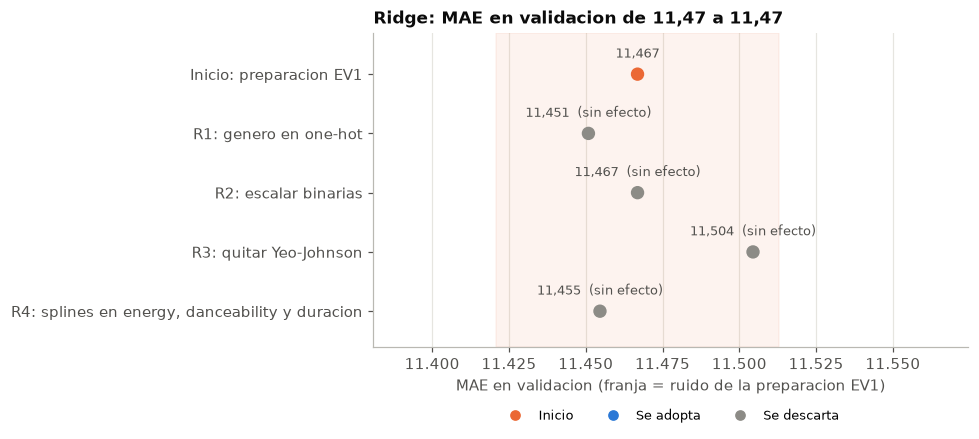

In [13]:
resumen_modelo('ridge', ridge)
grafico_recorrido('ridge', '5_1_recorrido_ridge')

**Ridge, resumen.** Ninguno de los cuatro cambios supero el ruido: la preparacion de la EV1 ya era la adecuada para un modelo lineal. Ridge termina con la misma preparacion (16 columnas) y un MAE de validacion de 11,467.

## 5.2 Random Forest

Punto de partida: la preparacion de la EV1.

In [14]:
rf = dict(CFG_EV1)
r = evaluar('rf', rf)
print(f"Random Forest con la preparacion de la EV1: MAE {r['MAE']:.3f} (ruido {r['ruido']:.3f}) | RMSE {r['RMSE']:.3f} | R2 {r['R2']:.4f} | "
      f"{r['columnas']} columnas | {r['segundos']:.0f} s")

Random Forest con la preparacion de la EV1: MAE 10.916 (ruido 0.054) | RMSE 15.688 | R2 0.3876 | 16 columnas | 41 s


Este es el valor contra el que se mide el primer cambio.

### F1. Quitar Yeo-Johnson y escalado

- **Hipotesis.** A Random Forest no le cambia nada escalar ni transformar. Cada corte de un arbol compara "variable < umbral", y una transformacion que conserva el orden de los valores deja los mismos cortes posibles.
- **Fuente.** Documentacion: los arboles requieren "little data preparation" y otras tecnicas, no los arboles, necesitan normalizar $_{[13]}$.
- **Prueba.** `continuas` pasa de `yj_escalar` a `sin_cambio`, y el genero codificado por objetivo sin escalar.

In [15]:
rf = probar('rf', rf, 'F1', {'continuas': 'sin_cambio', 'genero': 'objetivo'}, 'quitar Yeo-Johnson y escalado', 'documentacion', en_empate='nueva')

,MAE,RMSE,R2,columnas,segundos
vigente,10.916,15.688,0.388,16.000,41.000
con el cambio,10.917,15.692,0.387,16.000,42.000


Cambio en MAE: +0.001 | ruido (sd del MAE entre folds): 0.054 | folds que mejoran: 3 de 5 -> sin efecto; se adopta: si


- **Evidencia.** El MAE pasa de 10,916 a 10,917 (+0,001), con un ruido de 0,054. Mejora en 3 de 5 folds.
- **Veredicto: confirmada.** Sin efecto. Como la documentacion dice que el paso no hace falta, se adopta la version mas simple: Random Forest recibe las variables sin transformar.
- **Costo de no hacerlo.** Ninguno en precision; se mantendrian dos pasos que el modelo no usa.

### F2. Genero en one-hot

- **Hipotesis.** El one-hot con 113 generos empeora a Random Forest. La documentacion lo recomienda para pocas categorias, y con 113 columnas cada corte solo puede separar un genero del resto.
- **Fuente.** Documentacion: el one-hot es "better suited for low cardinality" $_{[10]}$.
- **Prueba.** `genero` pasa de `objetivo` a `onehot`.

In [16]:
rf = probar('rf', rf, 'F2', {'genero': 'onehot'}, 'genero en one-hot', 'documentacion', en_empate='vigente')

,MAE,RMSE,R2,columnas,segundos
vigente,10.917,15.692,0.387,16.000,42.000
con el cambio,10.828,15.622,0.393,128.000,192.000


Cambio en MAE: -0.088 | ruido (sd del MAE entre folds): 0.055 | folds que mejoran: 5 de 5 -> mejora; se adopta: si


- **Evidencia.** El MAE baja de 10,917 a 10,828 (-0,088), con un ruido de 0,055. Mejora en los 5 folds. Con 128 columnas, la validacion cruzada tarda varias veces mas (los segundos estan en la tabla y cambian segun el equipo).
- **Veredicto: refutada, el one-hot mejora.** Posible explicacion (razonamiento, no verificada): la codificacion por objetivo resume cada genero en su popularidad media, y el bosque solo puede cortar por rangos de esa media. Con el one-hot, cada arbol puede separar un genero concreto cuando le sirve, y Random Forest prueba todas las columnas en cada corte (`max_features = 1,0`).
- **Costo de no hacerlo.** 0,09 puntos de MAE. A cambio, el modelo recibe 128 columnas en vez de 16.

### F3. Recuperar `instrumentalness` y `key`

- **Hipotesis.** La EV1 excluyo dos variables por razones propias de un modelo lineal: `instrumentalness` por su VIF junto a `es_instrumental`, y `key` porque necesitaba 11 columnas one-hot. Un arbol no sufre la colinealidad de la misma forma y puede usar `key` como un numero. Recuperarlas deberia mejorar un poco el resultado.
- **Fuente.** Hipotesis propia, a partir de las decisiones de la EV1.
- **Prueba.** `recuperar` pasa de no a si.

In [17]:
rf = probar('rf', rf, 'F3', {'recuperar': True}, 'recuperar instrumentalness y key', 'hipotesis propia (EV1)', en_empate='vigente')

,MAE,RMSE,R2,columnas,segundos
vigente,10.828,15.622,0.393,128.000,192.000
con el cambio,10.833,15.595,0.395,130.000,183.000


Cambio en MAE: +0.005 | ruido (sd del MAE entre folds): 0.079 | folds que mejoran: 2 de 5 -> sin efecto; se adopta: no


- **Evidencia.** El MAE pasa de 10,828 a 10,833 (+0,005), con un ruido de 0,079. Mejora en 2 de 5 folds.
- **Veredicto: no confirmada.** Las dos variables no agregan informacion que el modelo no tenga ya (`es_instrumental` resume a `instrumentalness`, y la EV1 ya mostro que `key` no se relaciona con la popularidad). Se descarta.
- **Costo de no hacerlo.** Ninguno.

,cambio probado,fuente,MAE antes,MAE despues,cambio MAE,ruido,folds que mejoran,veredicto,se adopta
paso,,,,,,,,,
F1,quitar Yeo-Johnson y escalado,documentacion,10.916,10.917,0.001,0.054,3,sin efecto,si
F2,genero en one-hot,documentacion,10.917,10.828,-0.088,0.055,5,mejora,si
F3,recuperar instrumentalness y key,hipotesis propia (EV1),10.828,10.833,0.005,0.079,2,sin efecto,no


Preparacion final: {'continuas': 'sin_cambio', 'binarias': 'sin_cambio', 'genero': 'onehot', 'splines': False, 'recuperar': False, 'sin_n_generos': False}
Columnas que recibe el modelo: 128


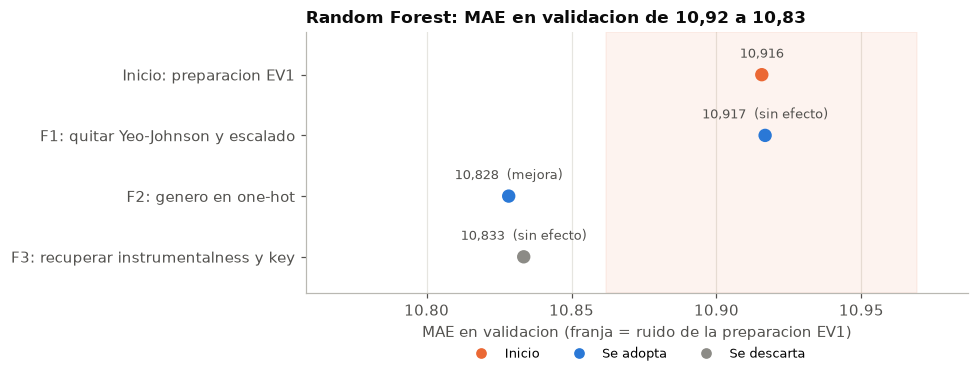

In [18]:
resumen_modelo('rf', rf)
grafico_recorrido('rf', '5_2_recorrido_rf')

**Random Forest, resumen.** Se adoptan dos cambios: variables sin transformar (F1, por simplicidad) y genero en one-hot (F2, por mejora). El MAE de validacion baja de 10,916 a 10,828.

## 5.3 XGBoost

Punto de partida: la preparacion de la EV1.

In [19]:
xgb = dict(CFG_EV1)
r = evaluar('xgb', xgb)
print(f"XGBoost con la preparacion de la EV1: MAE {r['MAE']:.3f} (ruido {r['ruido']:.3f}) | RMSE {r['RMSE']:.3f} | R2 {r['R2']:.4f} | {r['columnas']} columnas")

XGBoost con la preparacion de la EV1: MAE 11.281 (ruido 0.071) | RMSE 15.982 | R2 0.3643 | 16 columnas


Este es el valor contra el que se mide el primer cambio.

### X1. Quitar Yeo-Johnson y escalado

- **Hipotesis.** Igual que en Random Forest: un modelo de arboles no necesita escalar ni transformar.
- **Fuente.** Documentacion: los arboles requieren "little data preparation" $_{[13]}$.
- **Prueba.** `continuas` pasa de `yj_escalar` a `sin_cambio`, y el genero codificado por objetivo sin escalar.

In [20]:
xgb = probar('xgb', xgb, 'X1', {'continuas': 'sin_cambio', 'genero': 'objetivo'}, 'quitar Yeo-Johnson y escalado', 'documentacion', en_empate='nueva')

,MAE,RMSE,R2,columnas,segundos
vigente,11.281,15.982,0.364,16.000,5.000
con el cambio,11.299,16.021,0.361,16.000,2.000


Cambio en MAE: +0.018 | ruido (sd del MAE entre folds): 0.071 | folds que mejoran: 1 de 5 -> sin efecto; se adopta: si


- **Evidencia.** El MAE pasa de 11,281 a 11,299 (+0,018), con un ruido de 0,071. Mejora en 1 de 5 folds.
- **Veredicto: confirmada.** Sin efecto. Se adopta la version mas simple. La pequeña diferencia viene de que XGBoost agrupa los valores de cada variable en intervalos antes de buscar los cortes $_{[4]}$, y la transformacion mueve un poco los limites de esos intervalos (razonamiento).
- **Costo de no hacerlo.** Ninguno en precision.

### X2. Genero como categoria nativa

- **Hipotesis.** XGBoost mejora si recibe el genero como categoria. En cada corte puede agrupar los generos que dan predicciones parecidas, en vez de cortar solo por rangos de su popularidad media.
- **Fuente.** Documentacion: XGBoost busca agrupar "the categories that output similar leaf values" $_{[3]}$.
- **Prueba.** `genero` pasa de `objetivo` a `nativo` (columna `category`).

In [21]:
xgb = probar('xgb', xgb, 'X2', {'genero': 'nativo'}, 'genero como categoria nativa', 'documentacion', en_empate='nueva')

,MAE,RMSE,R2,columnas,segundos
vigente,11.299,16.021,0.361,16.000,2.000
con el cambio,10.655,15.663,0.390,16.000,2.000


Cambio en MAE: -0.644 | ruido (sd del MAE entre folds): 0.058 | folds que mejoran: 5 de 5 -> mejora; se adopta: si


- **Evidencia.** El MAE baja de 11,299 a 10,655 (-0,644), con un ruido de 0,058: 11 veces el ruido. Mejora en los 5 folds. El RMSE baja de 16,02 a 15,66 y el R² sube de 0,361 a 0,390.
- **Veredicto: confirmada.** Es el cambio de mayor efecto de todo el notebook. Se adopta.
- **Costo de no hacerlo.** 0,64 puntos de MAE: con la preparacion de la EV1, XGBoost queda detras de Random Forest.

### X3. Recuperar `instrumentalness` y `key`

- **Hipotesis.** Igual que F3: las razones para excluirlas eran propias de un modelo lineal.
- **Fuente.** Hipotesis propia, a partir de las decisiones de la EV1.
- **Prueba.** `recuperar` pasa de no a si.

In [22]:
xgb = probar('xgb', xgb, 'X3', {'recuperar': True}, 'recuperar instrumentalness y key', 'hipotesis propia (EV1)', en_empate='vigente')

,MAE,RMSE,R2,columnas,segundos
vigente,10.655,15.663,0.390,16.000,2.000
con el cambio,10.646,15.631,0.392,18.000,2.000


Cambio en MAE: -0.009 | ruido (sd del MAE entre folds): 0.085 | folds que mejoran: 2 de 5 -> sin efecto; se adopta: no


- **Evidencia.** El MAE pasa de 10,655 a 10,646 (-0,009), con un ruido de 0,085. Mejora en 2 de 5 folds.
- **Veredicto: no confirmada.** Se descarta.
- **Costo de no hacerlo.** Ninguno.

,cambio probado,fuente,MAE antes,MAE despues,cambio MAE,ruido,folds que mejoran,veredicto,se adopta
paso,,,,,,,,,
X1,quitar Yeo-Johnson y escalado,documentacion,11.281,11.299,0.018,0.071,1,sin efecto,si
X2,genero como categoria nativa,documentacion,11.299,10.655,-0.644,0.058,5,mejora,si
X3,recuperar instrumentalness y key,hipotesis propia (EV1),10.655,10.646,-0.009,0.085,2,sin efecto,no


Preparacion final: {'continuas': 'sin_cambio', 'binarias': 'sin_cambio', 'genero': 'nativo', 'splines': False, 'recuperar': False, 'sin_n_generos': False}
Columnas que recibe el modelo: 16


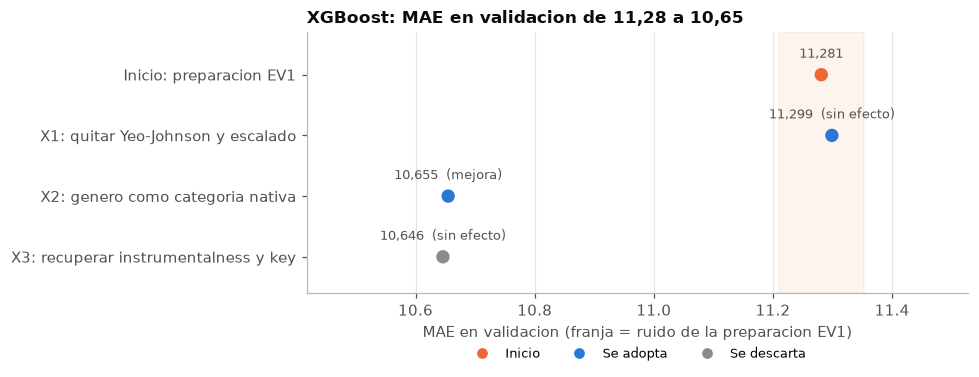

In [23]:
resumen_modelo('xgb', xgb)
grafico_recorrido('xgb', '5_3_recorrido_xgb')

**XGBoost, resumen.** Se adoptan dos cambios: variables sin transformar (X1, por simplicidad) y genero como categoria nativa (X2, por mejora). El MAE de validacion baja de 11,281 a 10,655.

## 5.4 Bitacora completa

Las diez hipotesis en una sola tabla, en el orden en que se probaron.

In [24]:
bitacora = pd.DataFrame(BITACORA).set_index(['modelo', 'paso'])
display(bitacora[['cambio probado', 'fuente', 'cambio MAE', 'ruido', 'folds que mejoran', 'veredicto', 'se adopta']])
print('Veredictos:', bitacora['veredicto'].value_counts().to_dict())

cambio probado                  fuente  cambio MAE  ruido  folds que mejoran   veredicto se adopta
modelo        paso                                                                                                                                
Ridge         R1                             genero en one-hot           documentacion      -0.016  0.046                  5  sin efecto        no
              R2                              escalar binarias           documentacion       0.000  0.046                  0  sin efecto        no
              R3                            quitar Yeo-Johnson           documentacion       0.038  0.046                  0  sin efecto        no
              R4    splines en energy, danceability y duracion  hipotesis propia (EDA)      -0.012  0.046                  5  sin efecto        no
Random Forest F1                 quitar Yeo-Johnson y escalado           documentacion       0.001  0.054                  3  sin efecto        si
              F2                             genero en one-hot           documentacion      -0.088  0.055                  5      mejora        si
              F3              recuperar instrumentalness y key  hipotesis propia (EV1)       0.005  0.079                  2  sin efecto        no
XGBoost       X1                 quitar Yeo-Johnson y escalado           documentacion       0.018  0.071                  1  sin efecto        si
              X2                  genero como categoria nativa           documentacion      -0.644  0.058                  5      mejora        si
              X3              recuperar instrumentalness y key  hipotesis propia (EV1)      -0.009  0.085                  2  sin efecto        no

Veredictos: {'sin efecto': 8, 'mejora': 2}


- **2 de 10 cambios mejoran** (F2 y X2), ambos sobre la forma de entregar el genero, que es la variable que mas pesa (9.1).
- **8 no tienen efecto.** De ellos, dos se adoptan por simplicidad (F1 y X1: los arboles no necesitan transformar) y seis se descartan.
- **Ningun cambio empeora mas que el ruido.** La preparacion de la EV1 no hacia daño a ningun modelo; solo dejaba sin aprovechar el genero en los arboles.

## 5.5 Todo junto

El paso a paso descarta un cambio si por separado no supera el ruido. Pero varios cambios pequeños podrian sumar, o complementarse, cuando se aplican a la vez. Por eso, al final, cada modelo se prueba con **todos los cambios propuestos juntos** y se compara con la preparacion del paso a paso.

- **Hipotesis.** Algun modelo mejora con todos los cambios a la vez, aunque por separado no hicieran nada.
- **Prueba.** Ridge: R1 + R2 + R4 (genero en one-hot, binarias y one-hot escaladas, splines), manteniendo Yeo-Johnson; R3 queda fuera porque quitarlo iba en contra de su hipotesis. Random Forest: F1 + F2 + F3. XGBoost: X1 + X2 + X3.
- **Regla.** La misma de 3.5: si mejora al paso a paso en mas que el ruido, la combinacion pasa a ser la preparacion final.

In [25]:
# Prueba final: todos los cambios propuestos a la vez, aunque por separado no hayan superado el ruido
# (puede que juntos sumen o se complementen). R3 queda fuera: quitar Yeo-Johnson iba en contra de su hipotesis.
TODO_JUNTO = {
    'ridge': ({**CFG_EV1, 'genero': 'onehot', 'binarias': 'escalar', 'splines': True}, 'R1 + R2 + R4'),
    'rf': ({**CFG_EV1, 'continuas': 'sin_cambio', 'genero': 'onehot', 'recuperar': True}, 'F1 + F2 + F3'),
    'xgb': ({**CFG_EV1, 'continuas': 'sin_cambio', 'genero': 'nativo', 'recuperar': True}, 'X1 + X2 + X3'),
}
PASO_A_PASO = {'ridge': ridge, 'rf': rf, 'xgb': xgb}
filas = []
for tipo, (cfg_todo, cambios) in TODO_JUNTO.items():
    e, p, t = evaluar(tipo, CFG_EV1), evaluar(tipo, PASO_A_PASO[tipo]), evaluar(tipo, cfg_todo)
    dif, ruido = t['MAE'] - p['MAE'], p['ruido']
    veredicto = 'mejora' if dif < -ruido else 'empeora' if dif > ruido else 'sin efecto'
    filas.append({'modelo': NOMBRES[tipo], 'cambios juntos': cambios, 'MAE EV1': e['MAE'], 'MAE paso a paso': p['MAE'],
                  'MAE todo junto': t['MAE'], 'todo junto - paso a paso': dif, 'ruido': ruido,
                  'folds que mejoran': int((t['MAE_folds'] < p['MAE_folds']).sum()), 'veredicto': veredicto,
                  'RMSE todo junto': t['RMSE'], 'columnas todo junto': t['columnas'],
                  'se adopta': 'si' if veredicto == 'mejora' else 'no'})
    if veredicto == 'mejora':
        PASO_A_PASO[tipo] = cfg_todo
ridge, rf, xgb = PASO_A_PASO['ridge'], PASO_A_PASO['rf'], PASO_A_PASO['xgb']
tabla_todo = pd.DataFrame(filas).set_index('modelo')
display(tabla_todo)
print('Preparaciones finales que pasan a la seccion 6:', {NOMBRES[k]: ('todo junto' if v is TODO_JUNTO[k][0] else 'paso a paso') for k, v in PASO_A_PASO.items()})

,cambios juntos,MAE EV1,MAE paso a paso,MAE todo junto,todo junto - paso a paso,ruido,folds que mejoran,veredicto,RMSE todo junto,columnas todo junto,se adopta
modelo,,,,,,,,,,,
Ridge,R1 + R2 + R4,11.467,11.467,11.433,-0.034,0.046,5,sin efecto,16.099,146,no
Random Forest,F1 + F2 + F3,10.916,10.828,10.833,0.005,0.079,2,sin efecto,15.595,130,no
XGBoost,X1 + X2 + X3,11.281,10.655,10.646,-0.009,0.085,2,sin efecto,15.631,18,no


Preparaciones finales que pasan a la seccion 6: {'Ridge': 'paso a paso', 'Random Forest': 'paso a paso', 'XGBoost': 'paso a paso'}


| Modelo | Cambios juntos | MAE paso a paso | MAE todo junto | Diferencia | Ruido | Folds que mejoran | Veredicto |
|---|---|---|---|---|---|---|---|
| Ridge | R1 + R2 + R4 | 11,467 | 11,433 | -0,034 | 0,046 | 5 de 5 | Sin efecto |
| Random Forest | F1 + F2 + F3 | 10,828 | 10,833 | +0,005 | 0,079 | 2 de 5 | Sin efecto |
| XGBoost | X1 + X2 + X3 | 10,655 | 10,646 | -0,009 | 0,085 | 2 de 5 | Sin efecto |

- **Evidencia.** En Ridge, los tres cambios juntos suman mas que cada uno por separado (-0,034 contra -0,016 y -0,012) y mejoran en los 5 folds, pero siguen bajo el ruido. A cambio, Ridge pasaria de 16 a 146 columnas. En los arboles, lo unico nuevo frente al paso a paso es recuperar `instrumentalness` y `key`, que tampoco aporta combinado.
- **Veredicto: no confirmada.** Ningun modelo mejora con todo junto. Los efectos pequeños si se suman en Ridge, pero no alcanzan a ser una mejora real.
- **Costo de no hacerlo.** Sin esta prueba quedaria la duda de si los cambios descartados servian combinados. Ahora esta medido: las preparaciones del paso a paso pasan sin cambios a la seccion 6.

---
# 6. Preparacion final contra la preparacion de la EV1

## 6.1 Variables finales por modelo

In [26]:
FINAL = {'ridge': ridge, 'rf': rf, 'xgb': xgb}
filas = []
for tipo, cfg in [(t, CFG_EV1) for t in FINAL] + list(FINAL.items()):
    pre = preparador(cfg).fit(datos(cfg, 'train'), y_train)
    nombres = list(pre.get_feature_names_out())
    filas.append({'modelo': NOMBRES[tipo], 'preparacion': 'EV1' if cfg is CFG_EV1 else 'final', 'columnas': len(nombres),
                  'columnas de genero': sum(n.startswith('track_genre') for n in nombres),
                  'continuas': cfg['continuas'], 'binarias': cfg['binarias'], 'genero': cfg['genero'],
                  'splines': cfg['splines'], 'recupera instrumentalness y key': cfg['recuperar']})
tabla_vars = pd.DataFrame(filas).set_index(['modelo', 'preparacion']).sort_index()
display(tabla_vars)

columnas  columnas de genero   continuas    binarias             genero  splines  recupera instrumentalness y key
modelo        preparacion                                                                                                                   
Random Forest EV1                16                   1  yj_escalar  sin_cambio  objetivo_escalado    False                            False
              final             128                 113  sin_cambio  sin_cambio             onehot    False                            False
Ridge         EV1                16                   1  yj_escalar  sin_cambio  objetivo_escalado    False                            False
              final              16                   1  yj_escalar  sin_cambio  objetivo_escalado    False                            False
XGBoost       EV1                16                   1  yj_escalar  sin_cambio  objetivo_escalado    False                            False
              final              16                   1  sin_cambio  sin_cambio             nativo    False                            False

| Modelo | Preparacion final | Columnas |
|---|---|---|
| Ridge | Igual a la EV1: Yeo-Johnson en 6 asimetricas, todo estandarizado salvo las binarias, genero codificado por objetivo | 16 |
| Random Forest | Variables sin transformar, genero en one-hot | 128 (113 de genero) |
| XGBoost | Variables sin transformar, genero como categoria nativa | 16 |

Las 15 variables que no son el genero son las mismas en los tres modelos: 11 continuas (`danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `liveness`, `valence`, `tempo`, `n_generos`, `duracion_min`, `n_artistas`) y 4 binarias (`explicit`, `mode`, `es_instrumental`, `compas_4_4`).

## 6.2 Entrenamiento y evaluacion en prueba

Cada modelo se entrena con todo el entrenamiento, con la preparacion de la EV1 y con la suya, y se evalua **una sola vez** en prueba.

In [27]:
CONFIGS = {}
for tipo in FINAL:
    CONFIGS[f'{tipo}_ev1'] = (tipo, CFG_EV1)
    CONFIGS[f'{tipo}_fin'] = (tipo, FINAL[tipo])
ETIQUETA = {i: f"{NOMBRES[t]} | {'EV1' if i.endswith('ev1') else 'preparacion propia'}" for i, (t, _) in CONFIGS.items()}

resultados, preds_test, modelos_ajustados = {}, {}, {}
for _id, (tipo, cfg) in CONFIGS.items():
    rcv = evaluar(tipo, cfg)
    m = armar(tipo, cfg).fit(datos(cfg, 'train'), y_train)
    p, p_tr = m.predict(datos(cfg, 'test')), m.predict(datos(cfg, 'train'))
    preds_test[_id], modelos_ajustados[_id] = p, m
    mt = metricas(y_test, p)
    resultados[_id] = {'configuracion': ETIQUETA[_id], 'MAE validacion': rcv['MAE'], 'ruido': rcv['ruido'], 'RMSE validacion': rcv['RMSE'],
                       'MAE test': mt['MAE'], 'RMSE test': mt['RMSE'], 'R2 test': mt['R2'], 'R2 train': r2_score(y_train, p_tr),
                       'MAE test exitos': mean_absolute_error(y_test[alta_test], p[alta_test])}

# Comprobacion: la EV1 rearmada entrega en prueba lo mismo que un modelo entrenado con los archivos procesado_ev1
m_archivos = crear_modelo('ridge').fit(X_proc_train, y_train)
print('Ridge EV1: rearmada = archivos procesado_ev1 en prueba:', np.allclose(m_archivos.predict(X_proc_test), preds_test['ridge_ev1']))

fila_base = {'configuracion': 'Linea base (media)', 'MAE test': m_base['MAE'], 'RMSE test': m_base['RMSE'], 'R2 test': m_base['R2'],
             'MAE test exitos': mae_exitos_base}
tabla_final = pd.DataFrame([fila_base] + list(resultados.values())).set_index('configuracion')
display(tabla_final)
print(f"Umbrales de exito: MAE <= {umbral_mae:.2f} | RMSE <= {umbral_rmse:.2f}")

Ridge EV1: rearmada = archivos procesado_ev1 en prueba: True


,MAE test,RMSE test,R2 test,MAE test exitos,MAE validacion,ruido,RMSE validacion,R2 train
configuracion,,,,,,,,
Linea base (media),16.825,20.147,-0.000,41.194,NaN,NaN,NaN,NaN
Ridge | EV1,11.516,16.267,0.348,32.821,11.467,0.046,16.133,0.356
Ridge | preparacion propia,11.516,16.267,0.348,32.821,11.467,0.046,16.133,0.356
Random Forest | EV1,10.990,15.855,0.380,30.887,10.916,0.054,15.688,0.840
Random Forest | preparacion propia,10.846,15.756,0.388,29.950,10.828,0.079,15.622,0.921
XGBoost | EV1,11.299,16.037,0.366,30.859,11.281,0.071,15.982,0.544
XGBoost | preparacion propia,10.643,15.788,0.386,29.360,10.655,0.085,15.663,0.651


Umbrales de exito: MAE <= 13.46 | RMSE <= 15.51


- **La preparacion de la EV1 rearmada da en prueba exactamente lo mismo que un modelo entrenado con los archivos `procesado_ev1`.**
- **XGBoost con preparacion propia** tiene el menor MAE en validacion (10,655) y tambien en prueba (10,643).
- **Sobreajuste visible en los arboles.** R² de entrenamiento contra prueba: Random Forest propio 0,921 y 0,388; XGBoost propio 0,651 y 0,386; Ridge 0,356 y 0,348. Es lo esperable con parametros por defecto (por ejemplo, `max_depth=None` $_{[5]}$).
- **Ningun modelo cumple el umbral de RMSE** (15,51); el mas cercano es Random Forest propio (15,76).

## 6.3 ¿Valio la pena adaptar la preparacion?

In [28]:
filas = []
for tipo in FINAL:
    a, b = resultados[f'{tipo}_ev1'], resultados[f'{tipo}_fin']
    pasos = [x for x in BITACORA if x['modelo'] == NOMBRES[tipo]]
    fila = {'modelo': NOMBRES[tipo], 'cambios adoptados': ', '.join(x['paso'] for x in pasos if x['se adopta'] == 'si') or 'ninguno',
            'MAE valid. EV1': a['MAE validacion'], 'MAE valid. propia': b['MAE validacion'], 'cambio valid.': b['MAE validacion'] - a['MAE validacion'],
            'ruido': a['ruido'], 'MAE test EV1': a['MAE test'], 'MAE test propia': b['MAE test'], 'cambio test': b['MAE test'] - a['MAE test'],
            'RMSE test EV1': a['RMSE test'], 'RMSE test propia': b['RMSE test']}
    fila['lectura'] = 'mejora real' if -fila['cambio valid.'] > fila['ruido'] else 'dentro del ruido'
    filas.append(fila)
tabla_comp = pd.DataFrame(filas).set_index('modelo')
display(tabla_comp)

orden_ev1 = sorted([f'{t}_ev1' for t in FINAL], key=lambda i: resultados[i]['MAE validacion'])
orden_fin = sorted([f'{t}_fin' for t in FINAL], key=lambda i: resultados[i]['MAE validacion'])
print('Orden por MAE de validacion con la preparacion EV1  :', [ETIQUETA[i].split(' |')[0] for i in orden_ev1])
print('Orden por MAE de validacion con la preparacion propia:', [ETIQUETA[i].split(' |')[0] for i in orden_fin])

,cambios adoptados,MAE valid. EV1,MAE valid. propia,cambio valid.,ruido,MAE test EV1,MAE test propia,cambio test,RMSE test EV1,RMSE test propia,lectura
modelo,,,,,,,,,,,
Ridge,ninguno,11.467,11.467,0.000,0.046,11.516,11.516,0.000,16.267,16.267,dentro del ruido
Random Forest,"F1, F2",10.916,10.828,-0.087,0.054,10.990,10.846,-0.144,15.855,15.756,mejora real
XGBoost,"X1, X2",11.281,10.655,-0.626,0.071,11.299,10.643,-0.656,16.037,15.788,mejora real


Orden por MAE de validacion con la preparacion EV1  : ['Random Forest', 'XGBoost', 'Ridge']
Orden por MAE de validacion con la preparacion propia: ['XGBoost', 'Random Forest', 'Ridge']


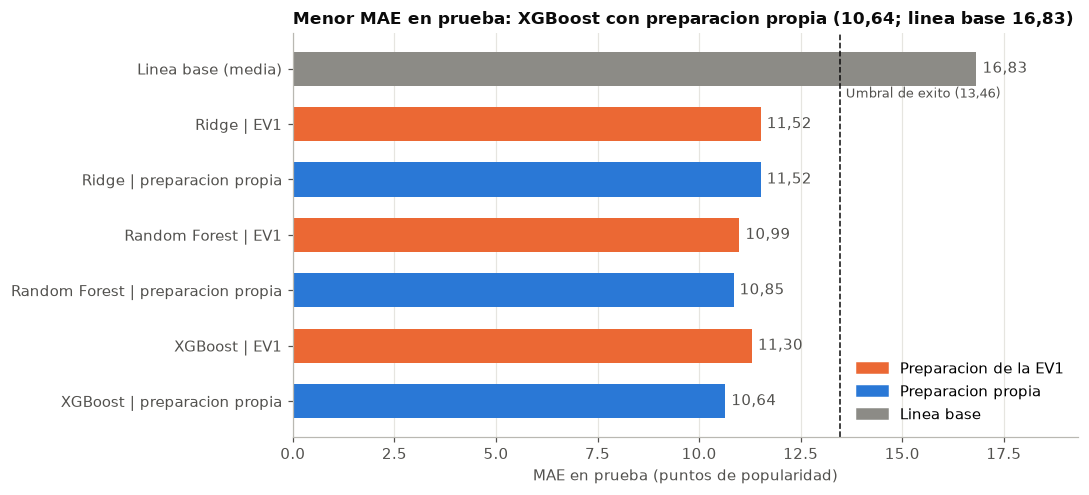

In [29]:
orden = ['base'] + [i for t in FINAL for i in (f'{t}_ev1', f'{t}_fin')]
valores = [m_base['MAE']] + [resultados[i]['MAE test'] for i in orden[1:]]
colores = [COLOR_NEUTRO] + [COLOR_EV1 if i.endswith('ev1') else COLOR_ADAPT for i in orden[1:]]
fig, ax = plt.subplots(figsize=(10, 4.6))
ypos = np.arange(len(orden))[::-1]
barras = ax.barh(ypos, valores, color=colores, height=0.62)
for b in barras:
    ax.text(b.get_width() + 0.15, b.get_y() + b.get_height() / 2, f'{b.get_width():.2f}'.replace('.', ','), va='center', color=COLOR_TEXTO)
ax.set_yticks(ypos); ax.set_yticklabels(['Linea base (media)'] + [ETIQUETA[i] for i in orden[1:]])
ax.axvline(umbral_mae, color='#0b0b0b', linestyle='--', linewidth=1)
ax.text(umbral_mae + 0.15, ypos[0] - 0.45, f"Umbral de exito ({umbral_mae:.2f})".replace('.', ','), fontsize=8.5, color=COLOR_TEXTO, va='center')
ax.set_xlim(0, max(valores) + 2.5)
mejor = min(orden[1:], key=lambda i: resultados[i]['MAE test'])
estilo(ax, f"Menor MAE en prueba: {NOMBRES[CONFIGS[mejor][0]]} con preparacion propia ({resultados[mejor]['MAE test']:.2f}; linea base {m_base['MAE']:.2f})".replace('.', ','),
       'MAE en prueba (puntos de popularidad)', None, grilla='x')
ax.title.set_fontsize(9.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COLOR_EV1, label='Preparacion de la EV1'), Patch(color=COLOR_ADAPT, label='Preparacion propia'),
                   Patch(color=COLOR_NEUTRO, label='Linea base')], frameon=False, loc='lower right')
plt.tight_layout(); guardar_figura(fig, '6_1_comparacion_mae'); plt.show()

| Modelo | Cambios adoptados | Validacion EV1 | Validacion propia | Prueba EV1 | Prueba propia | Lectura |
|---|---|---|---|---|---|---|
| Ridge | Ninguno | 11,467 | 11,467 | 11,516 | 11,516 | La preparacion de la EV1 ya era la adecuada |
| Random Forest | F1, F2 | 10,916 | 10,828 (-0,087) | 10,990 | 10,846 (-0,144) | Mejora real, pequeña |
| XGBoost | X1, X2 | 11,281 | 10,655 (-0,626) | 11,299 | 10,643 (-0,656) | Mejora real, la mayor |

*Cifras en MAE (puntos de popularidad).*

- **En prueba se repite lo que dijo la validacion:** el mismo signo y un tamaño parecido en los tres modelos.
- **La preparacion cambia el orden.** Con la preparacion de la EV1 el orden es Random Forest, XGBoost, Ridge. Con la preparacion propia es XGBoost, Random Forest, Ridge. Con una sola preparacion para todos, XGBoost se habria descartado por error.
- **Costo de no hacerlo.** Sin adaptar, el mejor modelo seria Random Forest con 10,99 de MAE en prueba, en vez de XGBoost con 10,64.

---
# 7. Errores, criterios de exito y protocolo de seleccion

## 7.1 Error por segmento de popularidad (prueba)

In [30]:
segs_test = {'Popularidad 0': y_test == 0, 'Popularidad 1 a 69': (y_test > 0) & (y_test < 70), 'Popularidad 70 o mas': y_test >= 70}
preds_todos = {'base': pred_base, **preds_test}
filas = []
for _id in orden:
    fila = {'configuracion': 'Linea base (media)' if _id == 'base' else ETIQUETA[_id]}
    for nombre, mask in segs_test.items():
        fila[f'MAE {nombre}'] = mean_absolute_error(y_test[mask], preds_todos[_id][mask])
    fila['sesgo en exitos (pred - real)'] = (preds_todos[_id][segs_test['Popularidad 70 o mas'].values] - y_test[segs_test['Popularidad 70 o mas']]).mean()
    filas.append(fila)
print('Canciones de prueba por segmento:', {k: int(v.sum()) for k, v in segs_test.items()})
display(pd.DataFrame(filas).set_index('configuracion'))

Canciones de prueba por segmento: {'Popularidad 0': 1316, 'Popularidad 1 a 69': 15182, 'Popularidad 70 o mas': 657}


,MAE Popularidad 0,MAE Popularidad 1 a 69,MAE Popularidad 70 o mas,sesgo en exitos (pred - real)
configuracion,,,,
Linea base (media),34.323,14.254,41.194,-41.194
Ridge | EV1,27.612,9.199,32.821,-32.821
Ridge | preparacion propia,27.612,9.199,32.821,-32.821
Random Forest | EV1,26.935,8.747,30.887,-30.887
Random Forest | preparacion propia,25.911,8.714,29.950,-29.950
XGBoost | EV1,26.735,9.115,30.859,-30.834
XGBoost | preparacion propia,25.278,8.564,29.360,-29.323


- Con XGBoost propio el MAE baja frente a la linea base de 34,3 a 25,3 en las 1.316 canciones con popularidad 0, de 14,3 a 8,6 en las 15.182 de 1 a 69 y de 41,2 a 29,4 en las 657 de 70 o mas.
- **Los exitos se subestiman de forma sistematica:** el sesgo (prediccion menos real) es de -29,3 puntos en XGBoost, -30,0 en Random Forest y -32,8 en Ridge.
- La preparacion propia mejora a los arboles en los tres segmentos.

## 7.2 Equidad entre generos y criterios de exito (prueba)

Los generos se ordenan por su popularidad media en entrenamiento y las canciones de prueba se reparten en cuatro cuartiles. El criterio pide una brecha de MAE de 5 puntos o menos entre el cuartil con mas error y el de menos.

In [31]:
media_genero_train = y_train.groupby(X_base_train['track_genre']).mean()
cuartil = pd.qcut(X_base_test['track_genre'].map(media_genero_train), q=4, labels=['Q1 (menos populares)', 'Q2', 'Q3', 'Q4 (mas populares)'])
filas, brechas = [], {}
for _id in orden:
    err = pd.Series(np.abs(y_test.values - preds_todos[_id]), index=y_test.index)
    por_q = err.groupby(cuartil.values, observed=True).mean()
    fila = {'configuracion': 'Linea base (media)' if _id == 'base' else ETIQUETA[_id], **por_q.to_dict()}
    fila['brecha (max - min)'] = por_q.max() - por_q.min()
    filas.append(fila)
    brechas[_id] = fila['brecha (max - min)']
display(pd.DataFrame(filas).set_index('configuracion'))

,Q1 (menos populares),Q2,Q3,Q4 (mas populares),brecha (max - min)
configuracion,,,,,
Linea base (media),19.091,14.016,14.188,20.093,6.077
Ridge | EV1,8.427,12.835,12.234,12.610,4.408
Ridge | preparacion propia,8.427,12.835,12.234,12.610,4.408
Random Forest | EV1,8.307,11.917,11.686,12.093,3.785
Random Forest | preparacion propia,8.074,11.842,11.499,12.014,3.940
XGBoost | EV1,8.424,12.228,12.110,12.479,4.054
XGBoost | preparacion propia,7.837,11.566,11.393,11.821,3.984


In [32]:
filas, cumple = [], []
for _id in CONFIGS:
    r_ = resultados[_id]
    v = {'R2 test': r_['R2 test'], 'RMSE test': r_['RMSE test'], 'MAE test': r_['MAE test'],
         'brecha R2 (train - test)': r_['R2 train'] - r_['R2 test'], 'MAE exitos (70 o mas)': r_['MAE test exitos'],
         'brecha MAE cuartiles de genero': brechas[_id]}
    c = {'R2 test': v['R2 test'] >= 0.40, 'RMSE test': v['RMSE test'] <= umbral_rmse, 'MAE test': v['MAE test'] <= umbral_mae,
         'brecha R2 (train - test)': v['brecha R2 (train - test)'] <= 0.05, 'MAE exitos (70 o mas)': v['MAE exitos (70 o mas)'] <= 20,
         'brecha MAE cuartiles de genero': v['brecha MAE cuartiles de genero'] <= 5}
    filas.append(pd.Series(v, name=ETIQUETA[_id])); cumple.append(pd.Series({k: 'si' if ok else 'no' for k, ok in c.items()}, name=ETIQUETA[_id]))
tabla_kpi, tabla_cumple = pd.DataFrame(filas), pd.DataFrame(cumple)
umbral = pd.DataFrame([{'R2 test': '>= 0,40', 'RMSE test': f"<= {umbral_rmse:.2f}", 'MAE test': f"<= {umbral_mae:.2f}",
                        'brecha R2 (train - test)': '<= 0,05', 'MAE exitos (70 o mas)': '<= 20', 'brecha MAE cuartiles de genero': '<= 5'}], index=['UMBRAL'])
display(tabla_kpi); display(pd.concat([umbral, tabla_cumple]))

,R2 test,RMSE test,MAE test,brecha R2 (train - test),MAE exitos (70 o mas),brecha MAE cuartiles de genero
Ridge | EV1,0.348,16.267,11.516,0.009,32.821,4.408
Ridge | preparacion propia,0.348,16.267,11.516,0.009,32.821,4.408
Random Forest | EV1,0.380,15.855,10.990,0.459,30.887,3.785
Random Forest | preparacion propia,0.388,15.756,10.846,0.533,29.950,3.940
XGBoost | EV1,0.366,16.037,11.299,0.178,30.859,4.054
XGBoost | preparacion propia,0.386,15.788,10.643,0.265,29.360,3.984


,R2 test,RMSE test,MAE test,brecha R2 (train - test),MAE exitos (70 o mas),brecha MAE cuartiles de genero
UMBRAL,">= 0,40",<= 15.51,<= 13.46,"<= 0,05",<= 20,<= 5
Ridge | EV1,no,no,si,si,no,si
Ridge | preparacion propia,no,no,si,si,no,si
Random Forest | EV1,no,no,si,no,no,si
Random Forest | preparacion propia,no,no,si,no,no,si
XGBoost | EV1,no,no,si,no,no,si
XGBoost | preparacion propia,no,no,si,no,no,si


- **Se cumplen** el MAE (6 de 6 configuraciones) y la equidad entre generos (6 de 6, con brechas de 3,8 a 4,4; la linea base tiene 6,1).
- **No se cumplen** el RMSE (0 de 6), el R² (0 de 6; el mejor es 0,388 contra 0,40) ni el MAE en exitos (0 de 6; el mejor es 29,4 contra 20). R² y RMSE son la misma exigencia vista de dos formas, por eso fallan juntos.
- **Sobreajuste:** solo Ridge cumple la brecha de R² (0,009). La preparacion propia la aumenta en los arboles: Random Forest pasa de 0,459 a 0,533 y XGBoost de 0,178 a 0,265. Las variables mejor entregadas tambien le permiten al arbol memorizar mas el entrenamiento; controlarlo corresponde al ajuste de hiperparametros.

## 7.3 Protocolo de seleccion aplicado

Se aplican, en orden, los cuatro pasos fijados en 3.5.

In [33]:
# Protocolo de seleccion (fijado en la seccion 3.5, antes de entrenar)
propias = {f'{t}_fin': NOMBRES[t] for t in FINAL}
INTERPRETABILIDAD = {'ridge_fin': 0, 'rf_fin': 1, 'xgb_fin': 1}   # 0 = coeficientes legibles; 1 = ensamble de arboles

# Paso 1: solo es apta una configuracion propia que cumple los seis criterios en prueba
aptas = [i for i in propias if (tabla_cumple.loc[ETIQUETA[i]] == 'si').all()]
print('Paso 1. Configuraciones que cumplen los seis criterios:', [propias[i] for i in aptas] or 'ninguna')

# Paso 2: entre las que compiten, la de menor MAE en validacion (si ninguna es apta, compiten las tres para candidata)
compiten = aptas if aptas else list(propias)
mae_val = {i: resultados[i]['MAE validacion'] for i in compiten}
lider = min(mae_val, key=mae_val.get)
print(f"Paso 2. Menor MAE en validacion: {propias[lider]} ({mae_val[lider]:.3f})")

# Paso 3: empate = diferencia menor que el ruido del lider; en empate gana la mas interpretable
tolerancia = resultados[lider]['ruido']
empatadas = [i for i in compiten if mae_val[i] - mae_val[lider] <= tolerancia]
for i in compiten:
    print(f"   {propias[i]:14s} MAE validacion {mae_val[i]:.3f} | distancia al lider {mae_val[i] - mae_val[lider]:.3f} (tolerancia {tolerancia:.3f})")
elegida = min(empatadas, key=lambda i: (INTERPRETABILIDAD[i], mae_val[i]))
print(f"Paso 3. Empatadas con el lider: {[propias[i] for i in empatadas]} -> {propias[elegida]}")

# Paso 4: los umbrales no se bajan; sin aptas, la elegida es candidata para la etapa siguiente, no un modelo listo para usar
if aptas:
    print(f"Paso 4. Modelo apto: {propias[elegida]}")
else:
    print(f"Paso 4. Ninguna configuracion es apta. Mejor candidata para la etapa siguiente: {propias[elegida]}")
    print('Criterios que no cumple:', [k for k, v in tabla_cumple.loc[ETIQUETA[elegida]].items() if v == 'no'])
mejor_test = min(propias, key=lambda i: resultados[i]['MAE test'])
print('Menor MAE en prueba (solo para contrastar):', propias[mejor_test], '| coincide con la elegida:', mejor_test == elegida)
TIPO_CAND = CONFIGS[elegida][0]

Paso 1. Configuraciones que cumplen los seis criterios: ninguna
Paso 2. Menor MAE en validacion: XGBoost (10.655)
   Ridge          MAE validacion 11.467 | distancia al lider 0.812 (tolerancia 0.085)
   Random Forest  MAE validacion 10.828 | distancia al lider 0.174 (tolerancia 0.085)
   XGBoost        MAE validacion 10.655 | distancia al lider 0.000 (tolerancia 0.085)
Paso 3. Empatadas con el lider: ['XGBoost'] -> XGBoost
Paso 4. Ninguna configuracion es apta. Mejor candidata para la etapa siguiente: XGBoost
Criterios que no cumple: ['R2 test', 'RMSE test', 'brecha R2 (train - test)', 'MAE exitos (70 o mas)']
Menor MAE en prueba (solo para contrastar): XGBoost | coincide con la elegida: True


| Paso | Resultado |
|---|---|
| 1. ¿Alguna preparacion propia cumple los seis criterios? | Ninguna |
| 2. Menor MAE en validacion | XGBoost, 10,655 |
| 3. ¿Empate con el lider? (tolerancia: su ruido = 0,085) | No: Random Forest queda a 0,174 y Ridge a 0,812 |
| 4. Veredicto | **Ningun modelo es apto. XGBoost con preparacion propia es el mejor candidato** para la etapa de ajuste |

Al candidato le faltan cuatro criterios: R² (0,386 contra 0,40), RMSE (15,79 contra 15,51), brecha de R² (0,265 contra 0,05) y MAE en exitos (29,4 contra 20). Cumple el MAE (10,64 contra 13,46) y la equidad (4,0 contra 5). La prueba confirma la eleccion: tambien es el de menor MAE en prueba.

**Costo de no aplicar el protocolo.** Se habria presentado como modelo final uno que no cumple cuatro de los seis criterios fijados en la EV1. El protocolo separa "el mejor de los tres" de "listo para usar".

## 7.4 Error de la candidata medido en puntos

El MAE es un promedio. Para quien usa el modelo es mas util saber en cuantas canciones el error es chico o grande.

In [34]:
# Error de la candidata medido en puntos de popularidad, frente a la linea base (prueba)
errores_abs = {'Linea base (media)': np.abs(y_test.values - pred_base), ETIQUETA[elegida]: np.abs(y_test.values - preds_test[elegida])}
filas = []
for nombre, e in errores_abs.items():
    fila = {'configuracion': nombre, 'error medio (MAE)': e.mean(), 'error mediano': np.median(e)}
    for u in [5, 10, 20]:
        fila[f'% con error <= {u} puntos'] = (e <= u).mean() * 100
    fila['% con error > 30 puntos'] = (e > 30).mean() * 100
    filas.append(fila)
tabla_puntos = pd.DataFrame(filas).set_index('configuracion')
display(tabla_puntos.round(1))

,error medio (MAE),error mediano,% con error <= 5 puntos,% con error <= 10 puntos,% con error <= 20 puntos,% con error > 30 puntos
configuracion,,,,,,
Linea base (media),16.800,14.300,14.700,32.400,64.900,17.000
XGBoost | preparacion propia,10.600,6.400,41.800,64.500,83.800,7.800


- **Evidencia.** La mitad de las canciones queda a 6,4 puntos o menos de su popularidad real (14,3 con la linea base). El 41,8% queda a 5 puntos o menos, el 64,5% a 10 o menos y el 83,8% a 20 o menos; la linea base logra 14,7%, 32,4% y 64,9%. Solo el 7,8% de las canciones se equivoca en mas de 30 puntos (17,0% con la linea base).
- **Lectura.** El error medio (10,6) es mayor que el mediano porque unas pocas canciones, sobre todo los exitos, tienen errores grandes.

Prediccion promedio en el grupo de mayor popularidad real: {'xgb_fin': (np.float64(84.4), np.float32(44.1)), 'rf_fin': (np.float64(84.4), np.float64(44.1)), 'ridge_fin': (np.float64(84.4), np.float64(42.7))}
Prediccion promedio en canciones con popularidad 0: {'xgb_fin': np.float32(24.9), 'rf_fin': np.float64(25.9), 'ridge_fin': np.float64(27.6)}


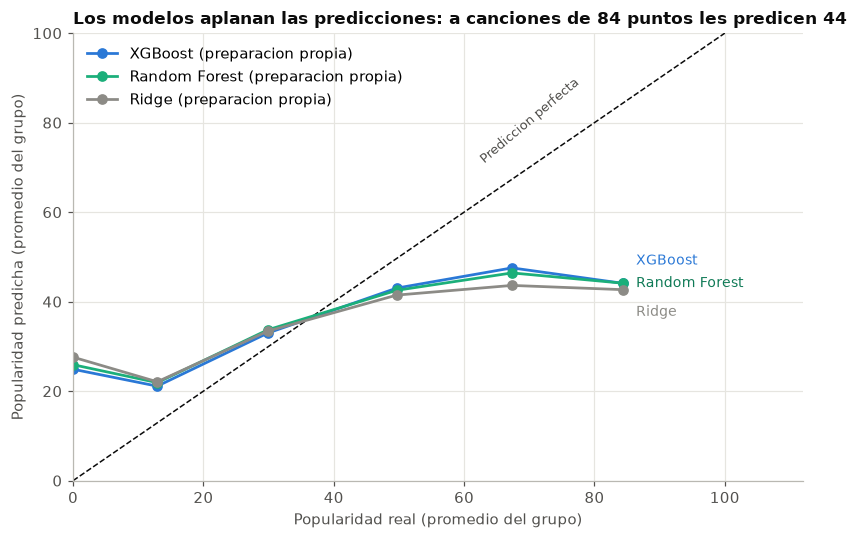

In [35]:
cortes = [-0.1, 0, 20, 40, 60, 80, 100]
grupo_real = pd.cut(y_test, cortes)
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot([0, 100], [0, 100], linestyle='--', color='#0b0b0b', linewidth=1)
ax.text(62, 71, 'Prediccion perfecta', fontsize=8.5, color=COLOR_TEXTO, rotation=40)
series = [('xgb_fin', 'XGBoost', COLOR_ADAPT, 5), ('rf_fin', 'Random Forest', '#1baf7a', 0), ('ridge_fin', 'Ridge', COLOR_NEUTRO, -5)]
extremos = {}
for _id, nombre, color, desplaza in series:
    t = pd.DataFrame({'real': y_test.values, 'pred': preds_test[_id]}).groupby(grupo_real.values, observed=True).mean()
    ax.plot(t['real'], t['pred'], marker='o', color=color, linewidth=1.8, label=f'{nombre} (preparacion propia)')
    ax.text(t['real'].iloc[-1] + 2, t['pred'].iloc[-1] + desplaza, nombre, color=color if color != '#1baf7a' else '#0f7a56', fontsize=9, va='center')
    extremos[_id] = {'real': t['real'].iloc[-1], 'pred': t['pred'].iloc[-1]}
ax.set_xlim(0, 112); ax.set_ylim(0, 100)
ax.legend(frameon=False, loc='upper left')
print('Prediccion promedio en el grupo de mayor popularidad real:', {k: (round(v['real'], 1), round(v['pred'], 1)) for k, v in extremos.items()})
cero = (y_test == 0).values
print('Prediccion promedio en canciones con popularidad 0:', {k: round(preds_test[k][cero].mean(), 1) for k, *_ in series})
estilo(ax, f"Los modelos aplanan las predicciones: a canciones de {extremos[elegida]['real']:.0f} puntos les predicen {extremos[elegida]['pred']:.0f}",
       'Popularidad real (promedio del grupo)', 'Popularidad predicha (promedio del grupo)', grilla='both')
ax.title.set_fontsize(9.5)
plt.tight_layout(); guardar_figura(fig, '7_1_predicho_vs_real'); plt.show()

Los modelos aplanan las predicciones: a canciones cuya popularidad real promedia 84,4 puntos, XGBoost y Random Forest les predicen 44,1 y Ridge 42,7; a las de popularidad 0, XGBoost les predice 24,9. Hipotesis (no verificada): audio y genero describen la popularidad tipica de un tipo de cancion, no lo que hace destacar a una en particular.

---
# 8. Escenario cancion inedita

`n_generos` cuenta en cuantos generos aparecia una cancion en las busquedas de Spotify. Una cancion que todavia no se publica no tiene ese dato, y el uso de negocio (decidir en que invertir antes del exito) es justamente ese caso.

- **Hipotesis.** Sin `n_generos` la candidata empeora un poco, porque es la segunda variable mas importante (9.1), pero sigue siendo util.
- **Prueba.** La preparacion final de la candidata se repite sin `n_generos`, con los mismos folds. La seleccion ya esta hecha; este escenario solo mide el costo de no tener la variable. Para comparar, se repite tambien en los otros dos modelos (solo en validacion).

In [36]:
# Escenario cancion inedita: n_generos solo existe cuando la cancion ya esta publicada y aparece en varias busquedas.
# Se repite la preparacion final de la candidata sin esa variable.
cfg_cand = FINAL[TIPO_CAND]
cfg_ined = {**cfg_cand, 'sin_n_generos': True}
r_con, r_sin = evaluar(TIPO_CAND, cfg_cand), evaluar(TIPO_CAND, cfg_ined)
m_ined = armar(TIPO_CAND, cfg_ined).fit(datos(cfg_ined, 'train'), y_train)
pred_ined = m_ined.predict(datos(cfg_ined, 'test'))
m_i = metricas(y_test, pred_ined)
r = resultados[elegida]
tabla_inedita = pd.DataFrame({
    'Con n_generos (candidata)': {'MAE validacion': r['MAE validacion'], 'ruido': r['ruido'], 'MAE test': r['MAE test'],
                                  'RMSE test': r['RMSE test'], 'R2 test': r['R2 test'], 'MAE test exitos': r['MAE test exitos']},
    'Sin n_generos (cancion inedita)': {'MAE validacion': r_sin['MAE'], 'ruido': r_sin['ruido'], 'MAE test': m_i['MAE'],
                                        'RMSE test': m_i['RMSE'], 'R2 test': m_i['R2'],
                                        'MAE test exitos': mean_absolute_error(y_test[alta_test], pred_ined[alta_test])},
}).T
tabla_inedita.loc['Diferencia (sin - con)'] = tabla_inedita.iloc[1] - tabla_inedita.iloc[0]
display(tabla_inedita.round(3))
costo = tabla_inedita.loc['Diferencia (sin - con)', 'MAE validacion']
print(f"Costo de no tener n_generos: {costo:.3f} puntos de MAE en validacion ({costo / r['ruido']:.1f} veces el ruido entre folds)")
# El mismo escenario en los tres modelos (solo validacion: la prueba se usa solo con la candidata)
filas = []
for tipo, cfg in FINAL.items():
    con, sin = evaluar(tipo, cfg), evaluar(tipo, {**cfg, 'sin_n_generos': True})
    filas.append({'modelo': NOMBRES[tipo], 'MAE valid. con n_generos': con['MAE'], 'MAE valid. sin n_generos': sin['MAE'],
                  'costo': sin['MAE'] - con['MAE'], 'ruido': con['ruido']})
display(pd.DataFrame(filas).set_index('modelo'))

,MAE validacion,ruido,MAE test,RMSE test,R2 test,MAE test exitos
Con n_generos (candidata),10.655,0.085,10.643,15.788,0.386,29.360
Sin n_generos (cancion inedita),10.903,0.058,10.844,15.933,0.374,29.307
Diferencia (sin - con),0.248,-0.027,0.201,0.145,-0.011,-0.053


Costo de no tener n_generos: 0.248 puntos de MAE en validacion (2.9 veces el ruido entre folds)


,MAE valid. con n_generos,MAE valid. sin n_generos,costo,ruido
modelo,,,,
Ridge,11.467,11.472,0.006,0.046
Random Forest,10.828,11.102,0.273,0.079
XGBoost,10.655,10.903,0.248,0.085


- **Evidencia.** Sin `n_generos`, el MAE de validacion de la candidata sube de 10,655 a 10,903 (+0,248, 2,9 veces el ruido) y el de prueba de 10,64 a 10,84. El RMSE pasa de 15,79 a 15,93 y el R² de 0,386 a 0,374; el error en exitos casi no cambia (de 29,4 a 29,3). Random Forest pierde algo parecido (+0,273) y Ridge casi nada (+0,006). Sin `n_generos`, XGBoost sigue siendo el mejor de los tres en validacion (10,903 contra 11,102 de Random Forest y 11,472 de Ridge).
- **Veredicto: confirmada.** `n_generos` aporta, pero poco frente al genero. Para una cancion inedita, la candidata pierde 0,25 puntos y sigue siendo la mejor opcion.
- **Costo de no hacerlo.** Sin este escenario, el modelo se usaria con una variable que una cancion nueva no tiene. La version sin `n_generos` es la que corresponde a ese uso.

---
# 9. Interpretacion del modelo candidato

Se hace despues de elegir, asi que no decide nada. Son **asociaciones, no causas**. Como `energy`, `loudness` y `acousticness` estan correlacionadas, su importancia se reparte entre ellas y ninguna se lee aislada.

## 9.1 Importancia por permutacion

Es la diferencia entre la metrica original y la metrica tras desordenar una columna $_{[11]}$: cuanto mas empeora el MAE de prueba, mas depende el modelo de esa variable. `track_genre` se desordena como una sola variable; 5 repeticiones.

,aumento del MAE,desviacion
track_genre,8.268,0.054
n_generos,0.467,0.029
energy,0.418,0.021
loudness,0.404,0.023
acousticness,0.372,0.019
duracion_min,0.344,0.025
danceability,0.307,0.021
valence,0.238,0.023
n_artistas,0.178,0.012
speechiness,0.156,0.013


Parte de la importancia total que corresponde al genero: 72.0%


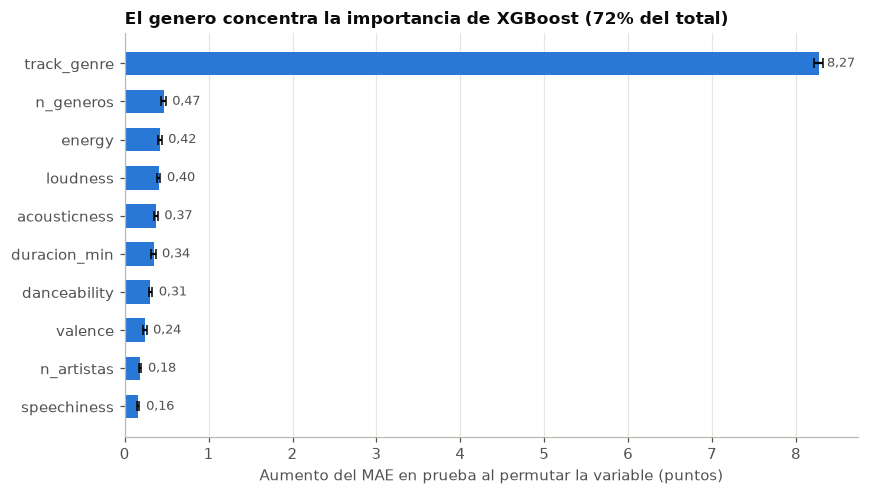

In [37]:
modelo_imp = modelos_ajustados[elegida]
X_imp = datos(FINAL[TIPO_CAND], 'test')[[c for c in cont + bin_ + ['track_genre'] + (EXTRA if FINAL[TIPO_CAND]['recuperar'] else [])]]
imp = permutation_importance(modelo_imp, X_imp, y_test, scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEMILLA, n_jobs=1)
tabla_imp = pd.DataFrame({'aumento del MAE': imp.importances_mean, 'desviacion': imp.importances_std}, index=X_imp.columns).sort_values('aumento del MAE', ascending=False)
display(tabla_imp)
pct_genero = tabla_imp.loc['track_genre', 'aumento del MAE'] / tabla_imp['aumento del MAE'].clip(lower=0).sum() * 100
print(f'Parte de la importancia total que corresponde al genero: {pct_genero:.1f}%')

top = tabla_imp.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top['aumento del MAE'], xerr=top['desviacion'], color=COLOR_ADAPT, height=0.62, capsize=3)
for y_, v_ in zip(range(len(top)), top['aumento del MAE']):
    ax.text(v_ + 0.1, y_, f'{v_:.2f}'.replace('.', ','), va='center', fontsize=8.5, color=COLOR_TEXTO)
estilo(ax, f"El genero concentra la importancia de {NOMBRES[TIPO_CAND]} ({pct_genero:.0f}% del total)", 'Aumento del MAE en prueba al permutar la variable (puntos)', None, grilla='x')
ax.title.set_fontsize(10.5)
plt.tight_layout(); guardar_figura(fig, '9_1_importancia_permutacion'); plt.show()

Desordenar el genero empeora el MAE en 8,27 puntos: el 72% de toda la importancia. La siguiente, `n_generos`, aporta 0,47, unas 18 veces menos. El audio aporta entre 0,42 (`energy`) y practicamente 0 (`mode`).

## 9.2 Anatomia de una prediccion

La importancia por permutacion es global. Para entender una prediccion concreta, XGBoost entrega el aporte de cada variable con `pred_contribs`: valores SHAP cuya suma es igual a la prediccion, mas un termino base $_{[12]}$.

Los aportes suman la prediccion del modelo: True
Valor base (punto de partida comun a todas las canciones): 34.3

Aporte medio absoluto por variable (puntos):
track_genre    9.400
energy         0.900
loudness       0.810
duracion_min   0.800
valence        0.790
n_generos      0.780

Cancion: If the World Was Ending - Acoustic (Jonah Baker;Celine), genero acoustic
Popularidad real 35 | prediccion 48.8
track_genre          9.240
energy               2.780
duracion_min         0.730
n_generos            0.660
danceability         0.410
n_artistas           0.300
resto de variables   0.400


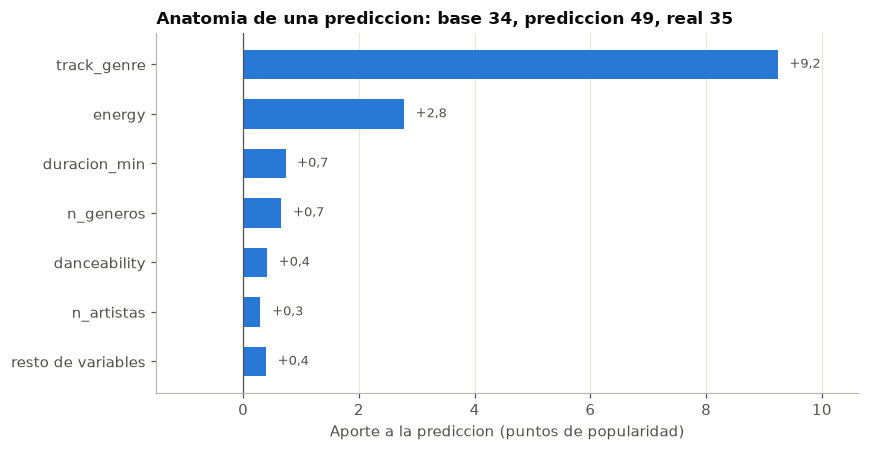

In [38]:
# Anatomia de una prediccion: aporte de cada variable a la prediccion de XGBoost (valores SHAP nativos, pred_contribs)
assert TIPO_CAND == 'xgb'
candidato = modelos_ajustados[elegida]
X_test_cand = datos(FINAL[TIPO_CAND], 'test')
X_transf = candidato.named_steps['pre'].transform(X_test_cand)
aportes = candidato.named_steps['modelo'].get_booster().predict(xgboost.DMatrix(X_transf, enable_categorical=True), pred_contribs=True)
aportes = pd.DataFrame(aportes, columns=list(X_transf.columns) + ['valor base'], index=X_test_cand.index)
print('Los aportes suman la prediccion del modelo:', np.allclose(aportes.sum(axis=1), candidato.predict(X_test_cand), atol=1e-3))
print(f"Valor base (punto de partida comun a todas las canciones): {aportes['valor base'].iloc[0]:.1f}")

aporte_medio = aportes.drop(columns='valor base').abs().mean().sort_values(ascending=False)
print('\nAporte medio absoluto por variable (puntos):')
print(aporte_medio.head(6).round(2).to_string())

# Lectura local: la cancion de prueba con la popularidad mas cercana a la mediana
ejemplo = (y_test - y_test.median()).abs().idxmin()
detalle = aportes.loc[ejemplo].drop('valor base')
principales = detalle.reindex(detalle.abs().sort_values(ascending=False).index).head(6)
principales['resto de variables'] = detalle.sum() - principales.sum()
print(f"\nCancion: {ids_test.loc[ejemplo, 'track_name']} ({ids_test.loc[ejemplo, 'artists']}), genero {X_base_test.loc[ejemplo, 'track_genre']}")
print(f"Popularidad real {y_test[ejemplo]} | prediccion {preds_test[elegida][ejemplo]:.1f}")
print(principales.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
orden_a = principales.iloc[::-1]
ax.barh(orden_a.index, orden_a.values, color=[COLOR_ADAPT if v > 0 else COLOR_EV1 for v in orden_a.values], height=0.6)
ax.axvline(0, color=COLOR_TEXTO, linewidth=0.8)
ax.set_xlim(min(orden_a.min() * 1.8, -1.5), max(orden_a.max() * 1.15, 1.5))   # espacio para las etiquetas
for y_, v_ in enumerate(orden_a.values):
    ax.text(v_ + (0.2 if v_ >= 0 else -0.2), y_, f'{v_:+.1f}'.replace('.', ','), va='center',
            ha='left' if v_ >= 0 else 'right', fontsize=8.5, color=COLOR_TEXTO)
estilo(ax, f"Anatomia de una prediccion: base {aportes['valor base'].iloc[0]:.0f}, prediccion {preds_test[elegida][ejemplo]:.0f}, real {y_test[ejemplo]}",
       'Aporte a la prediccion (puntos de popularidad)', None, grilla='x')
ax.title.set_fontsize(10)
plt.tight_layout(); guardar_figura(fig, '9_2_anatomia_prediccion'); plt.show()

- **Lectura global.** En promedio, el genero mueve la prediccion de una cancion en 9,4 puntos. Le siguen `energy` (0,90), `loudness` (0,81), `duracion_min` (0,80), `valence` (0,79) y `n_generos` (0,78). El genero domina con los dos metodos; el orden del resto cambia porque sus aportes son parecidos entre si.
- **Lectura local.** *If the World Was Ending - Acoustic* (Jonah Baker y Celine, genero `acoustic`) tiene popularidad real 35 y el modelo predice 48,8. La prediccion parte de un valor base de 34,3. El genero suma 9,2 y `energy` 2,8; el resto de las variables suma 2,5. Casi toda la diferencia con la realidad viene del genero: el modelo le asigna la popularidad tipica de las versiones acusticas, no la de esta cancion.
- **Para que sirve.** Cada prediccion se puede explicar variable por variable. Asi quien decide ve cuando el genero esta arrastrando la estimacion.

---
# 10. Auditoria de sesgos con el modelo

La EV1 mostro que el artista explica mas que el genero (efecto superestrella) y dejo como tarea revisar el error en artistas con pocas canciones.

- **Hipotesis.** Si el modelo hereda el efecto superestrella, deberia equivocarse mas o subestimar a los artistas con pocas canciones en el dataset.
- **Prueba.** MAE y sesgo (prediccion menos real) en prueba segun cuantas canciones tiene el artista principal en el dataset, contra la linea base.

,canciones test,popularidad real media,MAE linea base,MAE candidata,sesgo candidata (pred - real)
canciones del artista,,,,,
1 cancion,1381,39.030,14.570,11.300,-0.370
2 a 5,3996,36.510,15.660,10.650,0.310
6 a 20,5999,33.760,17.420,11.230,0.810
mas de 20,5779,33.310,17.560,9.870,-0.480


Brecha de MAE entre tramos: linea base 2.99 | candidata 1.43


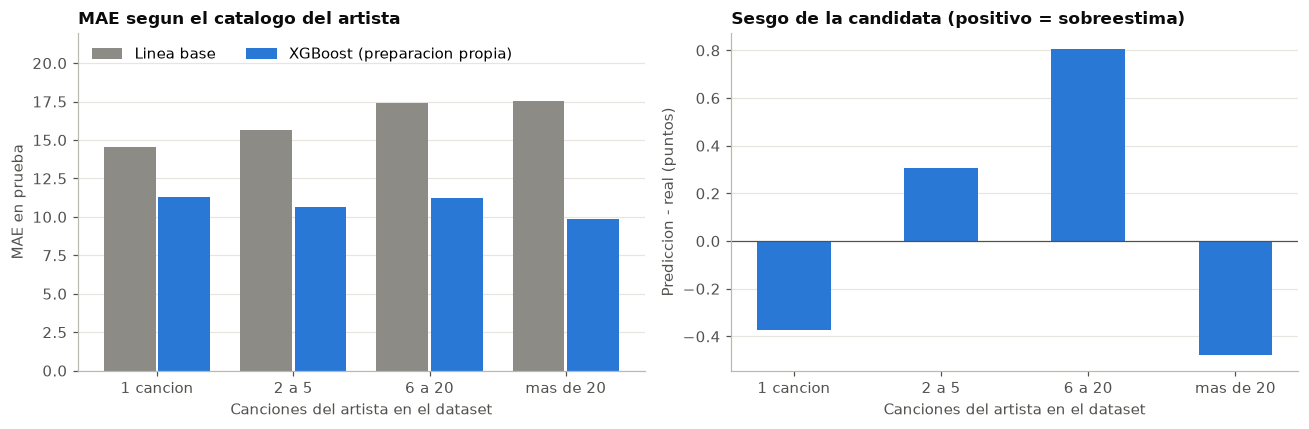

In [39]:
# Auditoria de sesgos con el modelo: error segun cuantas canciones tiene el artista principal en el dataset
artista_principal = pd.concat([ids_train, ids_test])['artists'].str.split(';').str[0]
catalogo = artista_principal.value_counts()
artista_test = ids_test['artists'].str.split(';').str[0]
tramo_catalogo = pd.cut(artista_test.map(catalogo), bins=[0, 1, 5, 20, 1000], labels=['1 cancion', '2 a 5', '6 a 20', 'mas de 20'])

pred_cand = pd.Series(preds_test[elegida], index=y_test.index)
base_serie = pd.Series(pred_base, index=y_test.index)
auditoria = pd.DataFrame({
    'canciones test': y_test.groupby(tramo_catalogo, observed=True).size(),
    'popularidad real media': y_test.groupby(tramo_catalogo, observed=True).mean(),
    'MAE linea base': (y_test - base_serie).abs().groupby(tramo_catalogo, observed=True).mean(),
    'MAE candidata': (y_test - pred_cand).abs().groupby(tramo_catalogo, observed=True).mean(),
    'sesgo candidata (pred - real)': (pred_cand - y_test).groupby(tramo_catalogo, observed=True).mean(),
})
auditoria.index.name = 'canciones del artista'
display(auditoria.round(2))
print(f"Brecha de MAE entre tramos: linea base {auditoria['MAE linea base'].max() - auditoria['MAE linea base'].min():.2f} "
      f"| candidata {auditoria['MAE candidata'].max() - auditoria['MAE candidata'].min():.2f}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(auditoria))
ejes[0].bar(x - 0.2, auditoria['MAE linea base'], 0.38, color=COLOR_NEUTRO, label='Linea base')
ejes[0].bar(x + 0.2, auditoria['MAE candidata'], 0.38, color=COLOR_ADAPT, label=f'{NOMBRES[TIPO_CAND]} (preparacion propia)')
ejes[1].bar(x, auditoria['sesgo candidata (pred - real)'], 0.5, color=COLOR_ADAPT)
ejes[1].axhline(0, color=COLOR_TEXTO, linewidth=0.8)
for ax in ejes:
    ax.set_xticks(x); ax.set_xticklabels(auditoria.index)
ejes[0].set_ylim(0, auditoria[['MAE linea base', 'MAE candidata']].values.max() * 1.25)   # espacio para la leyenda
ejes[0].legend(frameon=False, loc='upper left', ncol=2)
estilo(ejes[0], 'MAE segun el catalogo del artista', 'Canciones del artista en el dataset', 'MAE en prueba')
estilo(ejes[1], 'Sesgo de la candidata (positivo = sobreestima)', 'Canciones del artista en el dataset', 'Prediccion - real (puntos)')
plt.tight_layout(); guardar_figura(fig, '10_1_sesgo_artista'); plt.show()

- **Evidencia.** La candidata se equivoca entre 9,87 puntos (artistas con mas de 20 canciones) y 11,30 (artistas con una sola cancion). La brecha entre tramos es de 1,43, menos de la mitad de la de la linea base (2,99). El sesgo es pequeño y no tiene una direccion fija (entre -0,48 y +0,81 puntos).
- **Veredicto: hipotesis no confirmada en estos datos.** El modelo no castiga de forma visible a los artistas con pocas canciones. Matiz: tener una sola cancion en el dataset no equivale a ser un artista emergente. Esas canciones tienen la popularidad media mas alta (39,0), lo que calza con la seleccion por busqueda que describio la EV1.
- **Lo que no se puede medir.** El efecto superestrella de fondo (promocion, seguidores, fama) sigue fuera de los datos: el modelo no lo hereda de forma visible, pero tampoco lo corrige.
- **Equidad entre generos:** se cumple (7.2, brecha de 4,0 contra 5).

---
# 11. Conclusiones y recomendaciones

## 11.1 Respuesta a la pregunta de investigacion

Adaptar la preparacion **valio la pena en los dos modelos de arboles y no en Ridge**. XGBoost bajo su MAE de prueba de 11,30 a 10,64 y Random Forest de 10,99 a 10,85. En ambos casos el cambio que importa es como se entrega el genero. Para Ridge, la preparacion de la EV1 ya era la correcta. Con una sola preparacion para todos, XGBoost habria quedado detras de Random Forest y se habria descartado por error.

| Decision | Efecto medido (MAE de validacion) | ¿Valio la pena? |
|---|---|---|
| Genero como categoria nativa en XGBoost (X2) | -0,644 | Si |
| Genero en one-hot en Random Forest (F2) | -0,088 (con 112 columnas mas) | Si, aunque es pequeño |
| Quitar Yeo-Johnson y escalado en los arboles (F1, X1) | +0,001 y +0,018 | Si, como simplificacion: no hacia falta |
| Genero en one-hot en Ridge (R1) | -0,016 | No: el mismo resultado con 112 columnas mas |
| Escalar binarias en Ridge (R2) | 0,000 | No, con el `alpha` por defecto |
| Quitar Yeo-Johnson en Ridge (R3) | +0,038 | No: se mantiene Yeo-Johnson |
| Splines en Ridge (R4) | -0,012 | No: efecto real pero muy pequeño |
| Recuperar `instrumentalness` y `key` (F3, X3) | +0,005 y -0,009 | No |
| Todos los cambios juntos (5.5) | Ridge -0,034; Random Forest +0,005; XGBoost -0,009 | No: combinar no supera al paso a paso |
| Quitar `n_generos` (cancion inedita) | +0,248 en XGBoost | Costo pequeño y aceptable |

## 11.2 Veredicto del protocolo de seleccion

**Ningun modelo es apto todavia.** El mejor candidato es **XGBoost con el genero como categoria nativa y las variables sin transformar**: MAE de 10,64 en prueba (37% menos que la linea base, 16,83) y 10,66 en validacion. Cumple el MAE y la equidad, y le faltan R², RMSE, brecha de R² y error en exitos.

## 11.3 Que explica la popularidad

El **genero** concentra el 72% de la importancia y mueve cada prediccion en 9,4 puntos en promedio. El audio aporta efectos pequeños. Los exitos se subestiman en unos 29 puntos con cualquier modelo: lo que los distingue (fama, promocion) no esta en los datos.

## 11.4 Recomendaciones para el negocio

1. **Usarlo para ordenar y priorizar, no para decidir solo.** La mitad de las canciones queda a 6,4 puntos o menos de su popularidad real, pero el error medio es de 10,6.
2. **No usarlo para detectar exitos.** Los subestima en unos 29 puntos.
3. **Para canciones aun no publicadas, usar la version sin `n_generos`** (seccion 8).
4. **Acompañar cada prediccion con su anatomia** (aporte de cada variable) y con el error esperado de su genero.
5. **Antes de exigir mas precision, sumar datos de fama y promocion** (seguidores, fecha de lanzamiento, playlists).

---
# 12. Limitaciones, proximos pasos y reproducibilidad

## 12.1 Limitaciones

- **Parametros y perdida por defecto.** Se compara la preparacion, no modelos ajustados; el orden podria cambiar tras el ajuste (no verificado).
- **El orden de las hipotesis importa.** Cada cambio se probo sobre la preparacion vigente; otro orden podria dar otro resultado en los cambios pequeños. La prueba con todo junto (5.5) acota este riesgo: los cambios descartados tampoco mejoran combinados.
- **Cambios constantes pero pequeños.** En Ridge, R1, R2 y R4 juntos mejoran en los 5 folds (-0,034), pero menos que el ruido. Pueden ser efectos reales, demasiado pequeños para adoptarse con la regla fijada.
- **Un solo conjunto de prueba** (17.155 canciones, 657 exitos); no se estimo su ruido.
- **Decisiones de la EV1 tomadas con todo el dataset:** su EDA se hizo antes de dividir; es una fuga leve que ya no se puede evitar.
- **Muestra de Spotify:** 1.000 canciones por genero por construccion. Asociaciones, no causas.
- **El *cross fitting* de `TargetEncoder` no agrupa por cancion:** dos versiones de una cancion pueden compartir la media de su genero; el efecto es despreciable.

## 12.2 Proximos pasos (etapa siguiente)

1. **Ajuste de hiperparametros** con la misma validacion agrupada: `alpha` en Ridge; `max_depth`, `min_samples_leaf` y `max_features` en Random Forest; `eta`, `max_depth`, `subsample`, `colsample_bytree` y `lambda` en XGBoost. El objetivo principal es bajar el sobreajuste de los arboles (7.2).
2. **Elegir la funcion de perdida** como parte de ese ajuste: por ejemplo, la perdida absoluta de XGBoost optimiza directamente el MAE.
3. **Revisar R1 y R2 al subir `alpha`.** Con un castigo mayor, la escala de las binarias y del one-hot puede empezar a importar (razonamiento).
4. **Estimar el ruido de la prueba** con bootstrap por cancion.
5. **Enriquecer los datos** con seguidores del artista, fecha de lanzamiento y presencia en playlists.

## 12.3 Glosario tecnico

| Termino | Significado |
|---|---|
| MAE | Error absoluto medio: puntos que se equivoca el modelo en promedio |
| RMSE | Raiz del error cuadratico medio: como el MAE, pero castiga mas los errores grandes |
| R² | Parte de la variacion de la popularidad que explica el modelo (0 = predecir el promedio) |
| Linea base | Predecir siempre la media de entrenamiento |
| Validacion cruzada | Entrenar con 4 de 5 partes del entrenamiento y evaluar en la quinta, 5 veces |
| `GroupKFold` | Validacion cruzada que mantiene juntas las filas de un mismo grupo (aqui, una cancion) |
| `Pipeline` | Cadena preparacion + modelo que se reajusta completa en cada fold |
| Ruido | Desviacion del MAE entre los 5 folds; una diferencia menor no se considera real |
| Hiperparametro | Valor que se fija antes de entrenar (por ejemplo, `alpha` o `max_depth`); aqui se dejan por defecto |
| Bagging / boosting | Arboles en paralelo que se promedian / arboles en secuencia que corrigen a los anteriores |
| One-hot / por objetivo | Una columna 0/1 por categoria / cada categoria reemplazada por la media del objetivo |
| Categoria nativa | XGBoost recibe el genero como categoria y agrupa generos en cada corte |
| Splines | Curvas por tramos que permiten a un modelo lineal seguir una relacion curva |
| Importancia por permutacion | Cuanto empeora el error al desordenar una variable |
| Valores SHAP | Aporte de cada variable a una prediccion; suman la prediccion |
| Sobreajuste | Rendir mucho mejor en entrenamiento que en datos nuevos |

## 12.4 Reproducibilidad

1. Instalar las librerias con las versiones usadas: pandas 3.0.5, numpy 2.5.3, scikit-learn 1.9.1, xgboost 3.4.1, matplotlib 3.11.2, seaborn 0.13.2, jupyter 1.1.1 y nbconvert 7.17.2 (el comando esta en el `README.md`).
2. Ejecutar antes `ev1/notebook_ev1.ipynb`, que deja en `data/processed/` los 9 archivos que este notebook lee. Este notebook lee ademas `data/raw/Spotify_Tracks_Dataset.csv` para las hipotesis F3 y X3.
3. Ejecutar este notebook, desde `ev2/` o desde la raiz (sin rutas absolutas). Guarda las figuras en `ev2/images/` y no exporta otros archivos. Tarda unos 12 minutos (depende del equipo).

In [40]:
print(f'Python / pandas {pd.__version__} / numpy {np.__version__} / scikit-learn {sklearn.__version__} / xgboost {xgboost.__version__}')
print(f'Semilla: {SEMILLA} | validacion: GroupKFold(5) por cancion | modelos con parametros por defecto')
print('Los pasos que usan aleatoriedad (Random Forest, XGBoost, TargetEncoder) fijan random_state.')
print(f'Configuraciones evaluadas en validacion cruzada: {len(CACHE)}')
print(f'Figuras guardadas en {IMAGENES.relative_to(RAIZ).as_posix()}/: {len(list(IMAGENES.glob("*.png")))}')

Python / pandas 3.0.5 / numpy 2.5.3 / scikit-learn 1.9.1 / xgboost 3.4.1
Semilla: 42 | validacion: GroupKFold(5) por cancion | modelos con parametros por defecto
Los pasos que usan aleatoriedad (Random Forest, XGBoost, TargetEncoder) fijan random_state.
Configuraciones evaluadas en validacion cruzada: 17
Figuras guardadas en ev2/images/: 8


---
# Referencias

Documentacion oficial de cada libreria, version vigente (stable). Las citas textuales de scikit-learn se verificaron en la version 1.9.1.

[1] scikit-learn. *GroupKFold*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html
[2] scikit-learn. *User Guide: Linear Models, Ridge regression and classification*. https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification
[3] XGBoost. *Categorical Data*. https://xgboost.readthedocs.io/en/stable/tutorials/categorical.html
[4] XGBoost. *XGBoost Parameters*. https://xgboost.readthedocs.io/en/stable/parameter.html
[5] scikit-learn. *RandomForestRegressor*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html
[6] scikit-learn. *Ridge*. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html
[7] scikit-learn. *User Guide: Preprocessing data*. https://scikit-learn.org/stable/modules/preprocessing.html
[8] XGBoost. *Introduction to Boosted Trees*. https://xgboost.readthedocs.io/en/stable/tutorials/model.html
[9] scikit-learn. *PowerTransformer*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html
[10] scikit-learn. *TargetEncoder*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html
[11] scikit-learn. *permutation_importance*. https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html
[12] XGBoost. *Python API Reference: Booster.predict (`pred_contribs`)*. https://xgboost.readthedocs.io/en/stable/python/python_api.html
[13] scikit-learn. *User Guide: Decision Trees*. https://scikit-learn.org/stable/modules/tree.html
[14] scikit-learn. *SplineTransformer*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.SplineTransformer.html